# Visualisasi Data Geospasial pada Dataset Nyata: Kesenjangan Emisi CO2 dan Kemakmuran Ekonomi Antarnegara, 2022

| Keterangan | Isian |
|---|---|
| Nama | Muhammad Aulia Muzzaki Nugraha |
| NIM | 2311102051 |
| Kelas | IF-11-02 |
| Tugas | Visualisasi Data, Tugas Sub-CLO-12-2-2 |

Notebook ini menganalisis kesenjangan emisi karbon dioksida (CO2) dan kemakmuran ekonomi antarnegara pada tahun 2022 dengan memadukan batas negara Natural Earth dan data emisi Our World in Data. Seluruh angka pada tabel dan interpretasi dihitung dari berkas yang diunduh oleh notebook ini sendiri.

Urutan tahap: (1) deskripsi dataset, (2) persiapan data geospasial, (3) peta dasar, (4) choropleth, (5) multi-dimensi dan overlay, (6) kartogram dan animasi spatio-temporal, (7) insight, kesimpulan, dan rekomendasi, (8) deklarasi penggunaan AI, (9) daftar pustaka.

## Persiapan Lingkungan

### Tujuan

Sel berikut memasang pustaka dengan versi yang dipin sesuai kombinasi yang telah diuji (geopandas 1.2.0, geoplot 0.5.1, cartopy 0.26.0, mapclassify 2.11.0, shapely 2.2.0), kemudian mengimpor seluruh pustaka dan menampilkan versi yang benar-benar aktif. Pemasangan hanya mengunduh paket yang belum terpasang pada versi tersebut.

In [1]:
# Pemasangan pustaka dengan versi terpin (kombinasi yang telah diuji). Sel ini aman dijalankan ulang.
%pip install -q "geopandas==1.2.0" "geoplot==0.5.1" "cartopy==0.26.0" "mapclassify==2.11.0" "shapely==2.2.0" "matplotlib==3.11.2" "pandas==3.1.1" "numpy==2.5.5" "requests==2.34.2" "imageio==2.38.2" "pillow==13.0.0"
print("Pemasangan pustaka selesai.")

Note: you may need to restart the kernel to use updated packages.
Pemasangan pustaka selesai.


In [2]:
import math
import warnings
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import requests
import imageio
import imageio.v2 as iio
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import mapclassify as mc
import cartopy
import cartopy.crs as ccrs
import geoplot as gplt
import geoplot.crs as gcrs
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"font.size": 9, "axes.titlesize": 11, "figure.dpi": 100})

versi = pd.DataFrame(
    {
        "Pustaka": ["geopandas", "geoplot", "cartopy", "mapclassify", "shapely", "matplotlib",
                    "pandas", "numpy", "requests", "imageio"],
        "Versi": [gpd.__version__, gplt.__version__, cartopy.__version__, mc.__version__,
                  shapely.__version__, mpl.__version__, pd.__version__, np.__version__,
                  requests.__version__, imageio.__version__],
    }
)
display(versi)

,Pustaka,Versi
0,geopandas,1.2.0
1,geoplot,0.5.1
2,cartopy,0.26.0
3,mapclassify,2.11.0
4,shapely,2.2.0
5,matplotlib,3.11.2
6,pandas,3.1.1
7,numpy,2.5.5
8,requests,2.34.2
9,imageio,2.38.2


## Tahap 1. Deskripsi Dataset

### Tujuan

Tahap ini mengenalkan kedua komponen dataset, yaitu geometri batas negara dan atribut emisi, mencatat sumber, lisensi, serta tanggal akses, merumuskan tiga pertanyaan analisis, dan memvalidasi hasil penyaringan serta penggabungan data. Validasi mencakup jumlah baris pada tiap tahap dan perbandingan dengan nilai acuan hasil uji sebelumnya untuk Amerika Serikat, Tiongkok, India, dan Indonesia.

### Sumber dan lisensi

**Komponen 1, geometri.** Natural Earth 50m Admin 0 Countries, berformat GeoJSON dengan sistem koordinat EPSG:4326.
- Berkas: https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_50m_admin_0_countries.geojson
- Situs induk: https://www.naturalearthdata.com
- Lisensi: halaman Terms of Use (https://www.naturalearthdata.com/about/terms-of-use/, dibaca 24 November 2026) menyatakan seluruh data vektor dan raster Natural Earth berada di domain publik, tidak memerlukan izin pemakaian, dan pencantuman kredit tidak diwajibkan. Kredit yang disarankan penyedia berbunyi "Made with Natural Earth."
- Tanggal akses: 24 November 2026.
- Kolom kunci penggabungan: ADM0_A3.

**Komponen 2, atribut.** Our World in Data (OWID), *CO2 and Greenhouse Gas Emissions*, berformat CSV.
- Berkas: https://catalog.ourworldindata.org/emissions/owid_co2/owid_co2.csv (cadangan: https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv)
- Kodebook satuan dan deskripsi kolom: https://catalog.ourworldindata.org/emissions/owid_co2/owid_co2.codebook.csv
- Halaman induk: https://github.com/owid/co2-data
- Lisensi: README OWID menyatakan seluruh data yang diproduksi OWID terbuka di bawah lisensi Creative Commons BY, sedangkan data pihak ketiga tunduk pada lisensi asli pemiliknya. README juga meminta pengguna mengutip OWID sekaligus sumber data yang mendasarinya. Repositori GitHub tersebut tidak lagi diperbarui, sehingga berkas utama diambil dari katalog OWID.
- Kutipan sesuai petunjuk OWID pada README katalog: "Global Carbon Budget (2026) and other sources – with major processing by Our World in Data."
- Sumber asli menurut kodebook: seluruh variabel emisi (co2, co2_per_capita, share_global_co2, cumulative_co2) berasal dari Global Carbon Budget (2026) milik Global Carbon Project; GDP berasal dari Bolt dan van Zanden, Maddison Project Database 2023; populasi berasal dari sumber beragam yang dihimpun OWID (2024).
- Tanggal akses: 24 November 2026.

### Konteks

Emisi CO2 fosil dan proses industri merupakan penyumbang utama pemanasan global. Kodebook OWID menjelaskan bahwa variabel co2 mengukur emisi teritorial, yaitu emisi yang dihasilkan di dalam batas suatu negara, tanpa perubahan guna lahan, tanpa emisi barang impor, dan tanpa penerbangan serta pelayaran internasional yang hanya dihitung pada total global. Tahun 2022 dipilih karena GDP pada dataset ini hanya tersedia sampai 2022. Pemilihan tahun tersebut memastikan seluruh variabel numerik lengkap dalam satu potret waktu.

### Pertanyaan analisis

1. Negara mana yang menghasilkan emisi CO2 per kapita tertinggi?
2. Apakah emisi per kapita sejalan dengan pendapatan per kapita?
3. Seberapa besar pangsa segelintir negara penghasil emisi terbesar terhadap emisi global?

### Variabel

Satuan dibaca dari kodebook (ditampilkan pada Tahap 2). Variabel numerik riil: population (jiwa), gdp (international-$ harga 2011), co2 (juta ton, Mt), co2_per_capita (ton per orang), share_global_co2 (persen), dan cumulative_co2 (Mt). Variabel turunan dihitung dengan kode: gdp_per_kapita = gdp / population dan skor_co2_relatif = log10(co2_per_capita / median co2_per_capita seluruh negara terpilih).

Penyaringan dan penggabungan dijalankan pada tahap ini agar tabel validasi dapat disajikan di awal. Pemeriksaan satuan, variabel turunan, CRS, dan validitas geometri dilanjutkan pada Tahap 2.

In [3]:
# Lokasi kerja: notebook berada di notebooks/, sedangkan data dan keluaran berada di akar repository.
CWD = Path.cwd()
ROOT = CWD.parent if CWD.name == "notebooks" else CWD
RAW, PROC, FIG = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "outputs" / "figures"
for folder in (RAW, PROC, FIG):
    folder.mkdir(parents=True, exist_ok=True)

SUMBER = {
    "ne_50m_admin_0_countries.geojson": [
        "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_50m_admin_0_countries.geojson",
    ],
    "owid_co2.csv": [
        "https://catalog.ourworldindata.org/emissions/owid_co2/owid_co2.csv",
        "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv",  # cadangan
    ],
    "owid_co2.codebook.csv": [
        "https://catalog.ourworldindata.org/emissions/owid_co2/owid_co2.codebook.csv",
    ],
}


def unduh(nama, daftar_url, timeout=(15, 120)):
    """Mengunduh berkas ke data/raw bila belum ada; mengembalikan (status, url yang berhasil)."""
    tujuan = RAW / nama
    if tujuan.exists() and tujuan.stat().st_size > 0:
        return "salinan lokal dipakai", "-"
    for url in daftar_url:
        try:
            resp = requests.get(url, timeout=timeout, headers={"User-Agent": "geospatial-course-assignment/1.0"})
            resp.raise_for_status()
            if not resp.content:
                raise IOError("berkas unduhan kosong")
            tujuan.write_bytes(resp.content)
            return "diunduh", url
        except (requests.RequestException, IOError) as galat:
            print(f"Unduhan gagal dari {url}: {type(galat).__name__}: {galat}")
    return "GAGAL", "-"


baris = []
for nama, daftar_url in SUMBER.items():
    status, url_dipakai = unduh(nama, daftar_url)
    berkas = RAW / nama
    ada = berkas.exists()
    baris.append(
        {
            "berkas": nama,
            "status": status,
            "ukuran (MB)": round(berkas.stat().st_size / 1e6, 2) if ada else None,
            "tanggal unduh/akses": dt.date.fromtimestamp(berkas.stat().st_mtime).isoformat() if ada else None,
            "URL utama": daftar_url[0],
        }
    )
status_unduh = pd.DataFrame(baris)
display(status_unduh)

if (status_unduh["status"] == "GAGAL").any():
    raise RuntimeError(
        "Unduhan gagal. Unduh berkas secara manual dari URL pada tabel di atas dan simpan di folder "
        f"{RAW} dengan nama berkas yang sama, lalu jalankan ulang notebook."
    )
print("Seluruh berkas mentah tersedia di:", RAW)

,berkas,status,ukuran (MB),tanggal unduh/akses,URL utama
0,ne_50m_admin_0_countries.geojson,diunduh,3.08,2026-11-24,https://raw.githubusercontent.com/nvkelso/natu...
1,owid_co2.csv,diunduh,21.12,2026-11-24,https://catalog.ourworldindata.org/emissions/o...
2,owid_co2.codebook.csv,diunduh,0.07,2026-11-24,https://catalog.ourworldindata.org/emissions/o...


Seluruh berkas mentah tersedia di: D:\CODING\geospatial-data-visualization\data\raw


In [4]:
# Pembacaan berkas mentah. CSV atribut (sekitar 21 MB) hanya dibaca sekali.
df_all = pd.read_csv(RAW / "owid_co2.csv", low_memory=False)
kodebook = pd.read_csv(RAW / "owid_co2.codebook.csv")
world = gpd.read_file(RAW / "ne_50m_admin_0_countries.geojson")

TAHUN = 2022
KOLOM_WAJIB = ["population", "gdp", "co2", "co2_per_capita", "share_global_co2", "cumulative_co2"]
KOLOM_SIMPAN = ["iso_code", "country", "year"] + KOLOM_WAJIB

# Tahap penyaringan atribut
t0 = df_all
t1 = t0[t0["year"] == TAHUN]
t2 = t1[t1["iso_code"].notna()]
t3 = t2[~t2["iso_code"].str.startswith("OWID")]
t4 = t3.dropna(subset=KOLOM_WAJIB)
attr = t4[KOLOM_SIMPAN].copy()

# Penggabungan dengan geometri melalui ADM0_A3 = iso_code
assert world["ADM0_A3"].is_unique, "ADM0_A3 pada geometri tidak unik"
assert attr["iso_code"].is_unique, "iso_code pada atribut tidak unik"
gdf = world[["ADM0_A3", "NAME", "geometry"]].merge(
    attr, left_on="ADM0_A3", right_on="iso_code", how="inner", validate="one_to_one"
)
gdf = gpd.GeoDataFrame(gdf, geometry="geometry", crs=world.crs)
assert gdf["ADM0_A3"].is_unique, "Terdapat duplikasi setelah penggabungan"
assert len(gdf) >= 150, f"Hanya {len(gdf)} baris tergabung (minimal 150)"

kode_gagal = sorted(set(attr["iso_code"]) - set(world["ADM0_A3"]))
nama_gagal = attr.loc[attr["iso_code"].isin(kode_gagal), "country"].tolist()
print(f"Kode iso_code yang gagal tergabung dengan ADM0_A3: {kode_gagal} -> {nama_gagal}")

funnel = pd.DataFrame(
    [
        ("Seluruh baris CSV OWID (semua negara, wilayah, dan tahun)", len(t0)),
        (f"Baris tahun {TAHUN}", len(t1)),
        ("iso_code tidak kosong", len(t2)),
        ("Bukan agregat wilayah (iso_code tidak berawalan OWID)", len(t3)),
        ("Lengkap pada enam kolom wajib (negara terpilih)", len(t4)),
        ("Fitur geometri Natural Earth 50m (Admin 0)", len(world)),
        ("Negara tergabung dengan geometri (ADM0_A3 = iso_code)", len(gdf)),
        ("Negara lengkap yang tidak tergabung", len(kode_gagal)),
    ],
    columns=["Tahap", "Jumlah baris"],
)
funnel["Dibuang pada tahap ini"] = pd.array(
    [None, -(len(t0) - len(t1)), -(len(t1) - len(t2)), -(len(t2) - len(t3)), -(len(t3) - len(t4)), None, None, None],
    dtype="Int64")
display(funnel)

# Perbandingan dengan nilai acuan hasil uji sebelumnya (tahun 2022)
acuan = pd.DataFrame(
    {"iso_code": ["USA", "CHN", "IND", "IDN"], "co2_acuan_Mt": [5066, 11695, 2821, 752],
     "co2_per_kapita_acuan_t": [14.83, 8.21, 1.98, 2.70]}
)
cek = acuan.merge(attr[["iso_code", "country", "co2", "co2_per_capita"]], on="iso_code", how="left")
cek["selisih_co2_%"] = (cek["co2"] / cek["co2_acuan_Mt"] - 1) * 100
cek["selisih_per_kapita_%"] = (cek["co2_per_capita"] / cek["co2_per_kapita_acuan_t"] - 1) * 100
cek = cek[["country", "co2_acuan_Mt", "co2", "selisih_co2_%", "co2_per_kapita_acuan_t", "co2_per_capita",
           "selisih_per_kapita_%"]].rename(columns={"co2": "co2_hitung_Mt", "co2_per_capita": "co2_per_kapita_hitung_t"})
display(cek.round(2))
maks_selisih = cek[["selisih_co2_%", "selisih_per_kapita_%"]].abs().max().max()
assert maks_selisih <= 10, f"Selisih terhadap nilai acuan {maks_selisih:.1f}% (>10%): hentikan dan laporkan."
print(f"Selisih terbesar terhadap nilai acuan: {maks_selisih:.2f}% (batas toleransi 10%).")

Kode iso_code yang gagal tergabung dengan ADM0_A3: ['PSE'] -> ['Palestine']


,Tahap,Jumlah baris,Dibuang pada tahap ini
0,"Seluruh baris CSV OWID (semua negara, wilayah,...",56269,<NA>
1,Baris tahun 2022,259,-56010
2,iso_code tidak kosong,223,-36
3,Bukan agregat wilayah (iso_code tidak berawala...,223,0
4,Lengkap pada enam kolom wajib (negara terpilih),164,-59
5,Fitur geometri Natural Earth 50m (Admin 0),242,<NA>
6,Negara tergabung dengan geometri (ADM0_A3 = is...,163,<NA>
7,Negara lengkap yang tidak tergabung,1,<NA>


,country,co2_acuan_Mt,co2_hitung_Mt,selisih_co2_%,co2_per_kapita_acuan_t,co2_per_kapita_hitung_t,selisih_per_kapita_%
0,United States,5066,5065.99,-0.00,14.83,14.83,0.02
1,China,11695,11695.01,0.00,8.21,8.21,-0.05
2,India,2821,2821.41,0.01,1.98,1.98,-0.03
3,Indonesia,752,751.75,-0.03,2.70,2.70,-0.14


Selisih terbesar terhadap nilai acuan: 0.14% (batas toleransi 10%).


In [5]:
# Bukti pemilihan ADM0_A3 sebagai kunci (ISO_A3_EH tidak dipakai)
dup_eh = world[world["ISO_A3_EH"].duplicated(keep=False) & (world["ISO_A3_EH"] != "-99")]
print("Fitur dengan ISO_A3_EH ganda:", len(dup_eh), "-> kode:", sorted(dup_eh["ISO_A3_EH"].unique()), "-> fitur:", dup_eh["NAME"].tolist())
print("Fitur dengan ISO_A3_EH = -99 :", int((world["ISO_A3_EH"] == "-99").sum()))
print("ADM0_A3 unik                 :", world["ADM0_A3"].is_unique)
tahun_gdp_terakhir = int(df_all.loc[df_all["gdp"].notna(), "year"].max())
print(f"Tahun terakhir dengan GDP: {tahun_gdp_terakhir}; tahun terakhir pada CSV: {int(df_all['year'].max())}")

Fitur dengan ISO_A3_EH ganda: 3 -> kode: ['AUS'] -> fitur: ['Australia', 'Indian Ocean Ter.', 'Ashmore and Cartier Is.']
Fitur dengan ISO_A3_EH = -99 : 4
ADM0_A3 unik                 : True
Tahun terakhir dengan GDP: 2022; tahun terakhir pada CSV: 2025


### Hasil dan interpretasi

Berkas OWID memuat 56.269 baris untuk seluruh negara, wilayah, dan tahun, dengan tahun terakhir 2025. GDP baru tersedia sampai tahun 2022, sehingga 2022 menjadi tahun terbaru dengan variabel lengkap. Tahun 2022 memuat 259 baris. Sebanyak 223 baris memiliki iso_code, sedangkan 36 baris tanpa kode dibuang karena umumnya berupa agregat wilayah. Tidak ada kode berawalan OWID pada tahun 2022 di berkas ini, sehingga langkah tersebut tidak membuang baris tambahan.

Dari 223 negara, 164 memiliki keenam variabel wajib secara lengkap dan 59 negara dikeluarkan. Penggabungan dengan 242 fitur Natural Earth menghasilkan 163 negara tanpa duplikasi, melampaui batas minimum 150 baris. Satu-satunya kode yang gagal tergabung adalah PSE (Palestine), karena tidak ditemukan pada kolom ADM0_A3. Wilayah tersebut karenanya tidak muncul pada peta.

Seluruh nilai acuan lolos validasi. Selisih terbesar hanya 0,14 persen, yaitu emisi per kapita Indonesia, jauh di bawah toleransi 10 persen. Nilai yang dihitung adalah Amerika Serikat 5.065,99 Mt dan 14,83 t, Tiongkok 11.695,01 Mt dan 8,21 t, India 2.821,41 Mt dan 1,98 t, serta Indonesia 751,75 Mt dan 2,70 t. Berkas yang diunduh dengan demikian konsisten dengan hasil uji sebelumnya.

Pemeriksaan kunci menguatkan pilihan ADM0_A3. Kolom ISO_A3_EH memuat kode ganda AUS pada tiga fitur (Australia, Indian Ocean Ter., dan Ashmore and Cartier Is.) serta nilai -99 pada empat fitur, sedangkan ADM0_A3 unik pada seluruh fitur. Penggabungan satu-ke-satu karenanya dapat dijamin.

## Tahap 2. Persiapan Data Geospasial

### Tujuan

Tahap ini memeriksa satuan seluruh variabel pada kodebook, menghitung variabel turunan, menjelaskan sistem referensi koordinat (*Coordinate Reference System*, CRS), dan membuktikan bahwa geometri layak dipakai: bertipe Polygon atau MultiPolygon, tidak kosong, dan valid. Hasil gabungan kemudian disimpan ke data/processed/.

In [6]:
# Satuan dibaca dari kodebook OWID, bukan ditebak.
satuan = kodebook.set_index("column").loc[KOLOM_WAJIB, ["title", "unit", "source"]]
display(satuan)

,title,unit,source
column,,,
population,Population,people,Population based on various sources (2024)
gdp,Gross domestic product (GDP),international-$ in 2011 prices ($),Bolt and van Zanden – Maddison Project Databas...
co2,Annual CO₂ emissions,million tonnes (Mt),Global Carbon Budget (2026)
co2_per_capita,CO₂ emissions per capita,tonnes per person (t/person),Global Carbon Budget (2026); Population based ...
share_global_co2,Share of global annual CO₂ emissions,%,Global Carbon Budget (2026)
cumulative_co2,Cumulative CO₂ emissions,million tonnes (Mt),Global Carbon Budget (2026)


In [7]:
# Variabel turunan
assert (gdf["population"] > 0).all() and (gdf["co2_per_capita"] > 0).all()
gdf["gdp_per_kapita"] = gdf["gdp"] / gdf["population"]
MEDIAN_CO2PC = gdf["co2_per_capita"].median()
gdf["skor_co2_relatif"] = np.log10(gdf["co2_per_capita"] / MEDIAN_CO2PC)

print(f"Median co2_per_capita ({len(gdf)} negara terpilih): {MEDIAN_CO2PC:.4f} t/orang")
ringkas = gdf[["population", "gdp", "co2", "co2_per_capita", "share_global_co2", "cumulative_co2",
               "gdp_per_kapita", "skor_co2_relatif"]].describe().T
ringkas["skewness"] = gdf[ringkas.index].skew()
display(ringkas.round(3))

Median co2_per_capita (163 negara terpilih): 2.9100 t/orang


,count,mean,std,min,25%,50%,75%,max,skewness
population,163.0,4.849226e+07,1.624673e+08,6.684700e+04,4.659872e+06,1.123073e+07,3.528699e+07,1.425423e+09,7.682
gdp,163.0,7.991158e+11,2.782819e+12,6.750980e+08,3.514515e+10,1.019954e+11,4.860034e+11,2.696602e+13,7.392
co2,163.0,2.231230e+02,1.027933e+03,1.360000e-01,7.038000e+00,2.272300e+01,1.025050e+02,1.169501e+04,9.459
co2_per_capita,163.0,4.456000e+00,5.356000e+00,5.600000e-02,8.110000e-01,2.910000e+00,5.889000e+00,3.577100e+01,2.599
share_global_co2,163.0,5.950000e-01,2.743000e+00,0.000000e+00,1.900000e-02,6.100000e-02,2.740000e-01,3.121100e+01,9.459
cumulative_co2,163.0,1.057617e+04,4.141641e+04,3.671000e+00,1.994580e+02,9.952900e+02,5.054681e+03,4.244720e+05,7.839
gdp_per_kapita,163.0,1.923825e+04,2.007630e+04,6.889130e+02,4.415377e+03,1.265877e+04,2.743949e+04,1.319905e+05,2.011
skor_co2_relatif,163.0,-1.360000e-01,6.110000e-01,-1.715000e+00,-5.550000e-01,0.000000e+00,3.060000e-01,1.090000e+00,-0.565


In [8]:
print("CRS geometri Natural Earth :", world.crs)
print("CRS data gabungan           :", gdf.crs, "| kode EPSG:", gdf.crs.to_epsg())
print("Geografis (berderajat)?     :", gdf.crs.is_geographic, "| proyeksi (meter)?:", gdf.crs.is_projected)
for sumbu in gdf.crs.axis_info:
    print(f"  sumbu {sumbu.direction:6s}: {sumbu.name} ({sumbu.abbrev}), satuan = {sumbu.unit_name}")
print("Rentang koordinat (xmin, ymin, xmax, ymax):", np.round(gdf.total_bounds, 2))

CRS geometri Natural Earth : EPSG:4326
CRS data gabungan           : EPSG:4326 | kode EPSG: 4326
Geografis (berderajat)?     : True | proyeksi (meter)?: False
  sumbu north : Geodetic latitude (Lat), satuan = degree
  sumbu east  : Geodetic longitude (Lon), satuan = degree
Rentang koordinat (xmin, ymin, xmax, ymax): [-180.    -55.89  180.     83.12]


In [9]:
def periksa_geometri(g, nama):
    return pd.Series(
        {
            "jumlah fitur": len(g),
            "Polygon": int((g.geom_type == "Polygon").sum()),
            "MultiPolygon": int((g.geom_type == "MultiPolygon").sum()),
            "tipe lain": int((~g.geom_type.isin(["Polygon", "MultiPolygon"])).sum()),
            "geometri kosong": int(g.is_empty.sum()),
            "geometri null": int(g.isna().sum()),
            "valid": int(g.is_valid.sum()),
            "tidak valid": int((~g.is_valid).sum()),
        },
        name=nama,
    )


validasi_geom = pd.concat(
    [periksa_geometri(world.geometry, "Natural Earth 50m (seluruh fitur)"),
     periksa_geometri(gdf.geometry, "Negara terpilih (tergabung)")], axis=1
).T
display(validasi_geom)
for g in (world.geometry, gdf.geometry):
    assert set(g.geom_type) <= {"Polygon", "MultiPolygon"}
    assert not g.is_empty.any() and not g.isna().any() and g.is_valid.all()
print("Lolos: seluruh geometri bertipe Polygon atau MultiPolygon, tidak ada yang kosong, dan seluruhnya valid.")

,jumlah fitur,Polygon,MultiPolygon,tipe lain,geometri kosong,geometri null,valid,tidak valid
Natural Earth 50m (seluruh fitur),242,123,119,0,0,0,242,0
Negara terpilih (tergabung),163,83,80,0,0,0,163,0


Lolos: seluruh geometri bertipe Polygon atau MultiPolygon, tidak ada yang kosong, dan seluruhnya valid.


In [10]:
# Menyimpan hasil pemrosesan
gdf.to_file(PROC / "co2_2022_gabungan.geojson", driver="GeoJSON")
gdf.drop(columns="geometry").to_csv(PROC / "co2_2022_atribut.csv", index=False)
print("Tersimpan:", sorted(p.name for p in PROC.glob("*")))
display(gdf.drop(columns="geometry").head(5).round(3))

Tersimpan: ['co2_2022_atribut.csv', 'co2_2022_gabungan.geojson']


,ADM0_A3,NAME,iso_code,country,year,population,gdp,co2,co2_per_capita,share_global_co2,cumulative_co2,gdp_per_kapita,skor_co2_relatif
0,ZWE,Zimbabwe,ZWE,Zimbabwe,2022,16069061.0,2.590159e+10,12.256,0.763,0.033,804.298,1611.892,-0.582
1,ZMB,Zambia,ZMB,Zambia,2022,20152935.0,6.846960e+10,10.483,0.520,0.028,273.672,3397.500,-0.748
2,YEM,Yemen,YEM,Yemen,2022,38222878.0,6.085300e+10,20.950,0.548,0.056,731.533,1592.057,-0.725
3,VNM,Vietnam,VNM,Vietnam,2022,99680656.0,8.338039e+11,323.369,3.244,0.863,4993.135,8364.751,0.047
4,VEN,Venezuela,VEN,Venezuela,2022,28213015.0,1.496821e+11,108.390,3.842,0.289,7930.725,5305.426,0.121


### Hasil dan interpretasi

Satuan menurut kodebook adalah people (jiwa) untuk population, international-$ harga 2011 untuk gdp, juta ton (Mt) untuk co2 dan cumulative_co2, ton per orang untuk co2_per_capita, dan persen untuk share_global_co2. Kodebook mencatat Global Carbon Budget (2026) sebagai sumber seluruh variabel emisi, Maddison Project Database 2023 untuk GDP, dan sumber beragam yang dihimpun OWID (2024) untuk populasi.

Seluruh variabel miring ke kanan. Skewness co2_per_capita sebesar 2,60, sedangkan co2 dan share_global_co2 sebesar 9,46. Rata-rata co2_per_capita pada 163 negara adalah 4,46 t/orang dan melampaui mediannya, 2,91 t/orang. Median inilah yang menjadi acuan skor relatif. Skor berkisar dari -1,715 sampai 1,090, atau dari sekitar 0,019 kali sampai sekitar 12,3 kali median.

Sistem koordinat data adalah EPSG:4326 (WGS 84), yakni koordinat geografis dengan sumbu lintang dan bujur berdimensi derajat. Karena satuannya bukan meter, luas dan jarak tidak boleh dihitung langsung pada koordinat ini. Luas karenanya dihitung setelah transformasi ke proyeksi equal-area (EPSG:6933), dan peta digambar dengan proyeksi Equal Earth.

Geometri layak dipakai. Dari 242 fitur Natural Earth, 123 bertipe Polygon dan 119 MultiPolygon, tanpa tipe lain, tanpa geometri kosong, dan seluruhnya valid. Pada 163 negara terpilih terdapat 83 Polygon dan 80 MultiPolygon, juga seluruhnya valid. Hasil gabungan disimpan pada data/processed/.

## Tahap 3. Peta Dasar dengan Proyeksi Equal Earth

### Tujuan

Tahap ini menggambar batas negara dengan `gplt.polyplot` memakai `geoplot.crs.EqualEarth()` dan membandingkannya secara berdampingan dengan proyeksi Mercator.

Alasan memilih Equal Earth: cakupan analisis adalah seluruh dunia, dan pewarnaan choropleth membandingkan negara melalui luas bidang yang diwarnai. Proyeksi *equal-area* (luas sama) mempertahankan luas relatif antarnegara sehingga negara kecil dan besar tidak diberi bobot visual yang keliru. Distorsi bentuk pada Equal Earth tergolong moderat. Mercator bersifat konform, yakni mempertahankan sudut dan bentuk lokal, tetapi membesarkan luas wilayah lintang tinggi secara drastis. Mercator sesuai untuk navigasi, bukan untuk membandingkan besaran antarnegara.

Selain bentuk, perbedaan keduanya diukur secara kuantitatif: luas riil dihitung pada proyeksi equal-area EPSG:6933, sedangkan luas tampak dihitung pada EPSG:3857 (Web Mercator).

In [11]:
# Konfigurasi dan fungsi bantu peta
EXT = (-180, -58, 180, 86)  # catatan: nilai 85 membuat Cartopy menyempitkan rentang x (diuji), sehingga dipakai 86  # cakupan peta dunia tanpa Antartika (Equal Earth)
EXT_MERC = (-180, -58, 180, 84)  # Mercator membesar tajam di dekat kutub, sehingga dibatasi sampai lintang 84
CATATAN = ("Proyeksi: Equal Earth (equal-area); koordinat sumber EPSG:4326.\n"
           "Geometri: Natural Earth 50m (domain publik). Data: Our World in Data / Global Carbon Budget (CC BY), tahun 2022.")
dunia_bg = world[world["ADM0_A3"] != "ATA"]  # Antartika tidak digambar (tidak ada data emisi per negara)


def idn(x, nd=1):
    """Format angka bergaya Indonesia: pemisah ribuan titik, desimal koma."""
    teks = f"{x:,.{nd}f}"
    return teks.replace(",", "#").replace(".", ",").replace("#", ".")


def simpan(fig, nama):
    fig.savefig(FIG / nama, dpi=200, bbox_inches="tight", pad_inches=0.25, facecolor="white")
    print("Tersimpan:", (FIG / nama).relative_to(ROOT))


def catat(ax, teks=CATATAN):
    ax.annotate(teks, xy=(0, 0), xycoords="axes fraction", xytext=(0, -5), textcoords="offset points",
                va="top", ha="left", fontsize=6.5, color="#555555", wrap=True)


def latar(ax, proyeksi=None):
    """Lapisan dasar abu-abu: seluruh negara Natural Earth (negara tanpa data lengkap tetap tampak abu-abu)."""
    gplt.polyplot(dunia_bg, projection=proyeksi or gcrs.EqualEarth(), ax=ax, extent=EXT,
                  facecolor="#d9d9d9", edgecolor="white", linewidth=0.25)


def label_kelas(skema, y, nd=1):
    bawah = [float(np.min(y))] + [float(b) for b in skema.bins[:-1]]
    atas = [float(b) for b in skema.bins]
    return [f"{idn(a, nd)} – {idn(b, nd)}" for a, b in zip(bawah, atas)]


def peta_choropleth(ax, data, kolom, skema, cmap, judul, judul_legenda, labels, loc="lower left", edge="white"):
    # geoplot menormalkan warna berdasarkan rentang kelas yang teramati; pastikan kelas terendah dan tertinggi terisi.
    assert skema.yb.min() == 0 and skema.yb.max() == len(skema.bins) - 1, "kelas ujung kosong: warna bergeser"
    latar(ax)
    gplt.choropleth(data, hue=kolom, scheme=skema, cmap=cmap, projection=gcrs.EqualEarth(), ax=ax, extent=EXT,
                    edgecolor=edge, linewidth=0.3, legend=True, legend_labels=labels,
                    legend_kwargs={"loc": loc, "fontsize": 7.5, "title": judul_legenda, "title_fontsize": 8,
                                   "markersize": 7, "frameon": True})
    ax.set_title(judul, fontweight="bold", loc="left")
    catat(ax)


print(f"Fungsi bantu peta dimuat. Cakupan peta (bujur, lintang): {EXT}; lapisan dasar: {len(dunia_bg)} fitur tanpa Antartika.")

Fungsi bantu peta dimuat. Cakupan peta (bujur, lintang): (-180, -58, 180, 86); lapisan dasar: 241 fitur tanpa Antartika.


Tersimpan: outputs\figures\01_peta_dasar_equalearth_vs_mercator.png


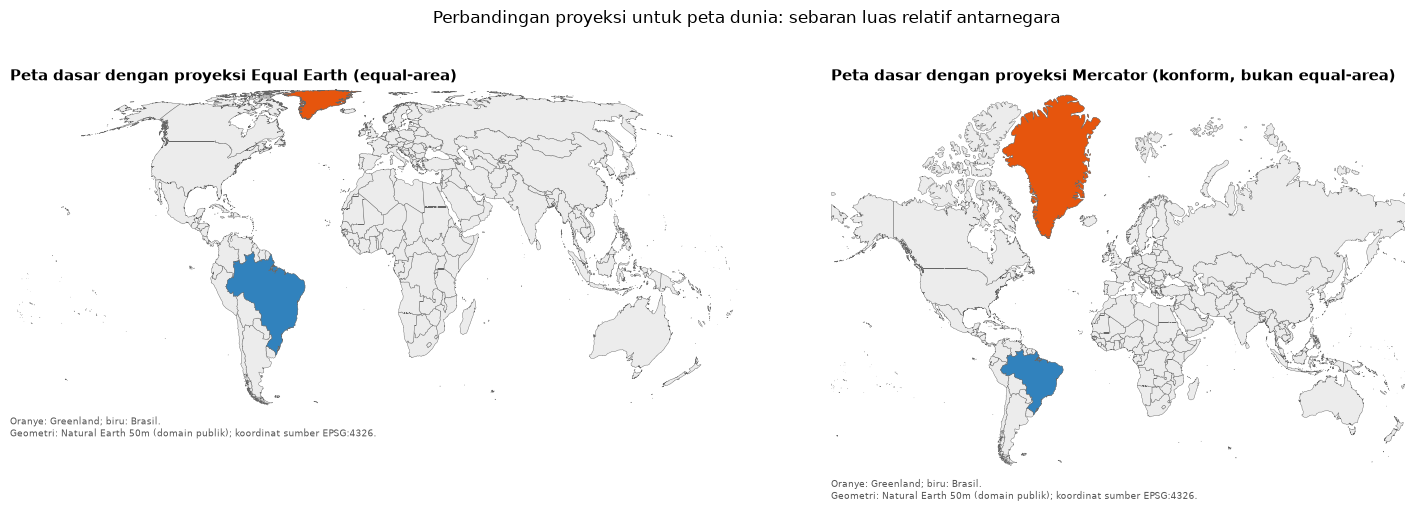

In [12]:
fig = plt.figure(figsize=(15, 4.9))
ax_eq = fig.add_subplot(1, 2, 1, projection=ccrs.EqualEarth())
ax_me = fig.add_subplot(1, 2, 2, projection=ccrs.Mercator())
for ax, proj, ext, jdl in [(ax_eq, gcrs.EqualEarth(), EXT, "Equal Earth (equal-area)"),
                           (ax_me, gcrs.Mercator(), EXT_MERC, "Mercator (konform, bukan equal-area)")]:
    ax.set_anchor("N")
    gplt.polyplot(dunia_bg, projection=proj, ax=ax, extent=ext, facecolor="#ececec", edgecolor="#666666", linewidth=0.3)
    gplt.polyplot(world[world["ADM0_A3"] == "GRL"], projection=proj, ax=ax, extent=ext, facecolor="#e6550d",
                  edgecolor="#666666", linewidth=0.3)
    gplt.polyplot(world[world["ADM0_A3"] == "BRA"], projection=proj, ax=ax, extent=ext, facecolor="#3182bd",
                  edgecolor="#666666", linewidth=0.3)
    ax.set_title(f"Peta dasar dengan proyeksi {jdl}", fontweight="bold", loc="left")
    catat(ax, "Oranye: Greenland; biru: Brasil.\nGeometri: Natural Earth 50m (domain publik); koordinat sumber EPSG:4326.")
fig.suptitle("Perbandingan proyeksi untuk peta dunia: sebaran luas relatif antarnegara", y=0.98, fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95))
simpan(fig, "01_peta_dasar_equalearth_vs_mercator.png")
plt.show()

In [13]:
# Luas riil (proyeksi equal-area EPSG:6933) dibandingkan dengan luas tampak pada Mercator (EPSG:3857)
pilih = world[world["ADM0_A3"].isin(["GRL", "BRA", "IDN"])].set_index("NAME")
luas_riil = pilih.to_crs("EPSG:6933").area / 1e6
luas_merc = pilih.to_crs("EPSG:3857").area / 1e6
tabel_luas = pd.DataFrame({"luas riil (km²)": luas_riil, "luas tampak Mercator (km²)": luas_merc})
tabel_luas["faktor pembesaran Mercator"] = tabel_luas["luas tampak Mercator (km²)"] / tabel_luas["luas riil (km²)"]
display(tabel_luas.round(2))
rasio_riil = luas_riil["Greenland"] / luas_riil["Brazil"]
rasio_merc = luas_merc["Greenland"] / luas_merc["Brazil"]
print(f"Rasio luas Greenland terhadap Brasil -> riil: {rasio_riil:.2f}; tampak pada Mercator: {rasio_merc:.2f}")

,luas riil (km²),luas tampak Mercator (km²),faktor pembesaran Mercator
NAME,,,
Indonesia,1863909.17,1885416.58,1.01
Greenland,2171413.39,35395740.77,16.30
Brazil,8467098.25,9012982.61,1.06


Rasio luas Greenland terhadap Brasil -> riil: 0.26; tampak pada Mercator: 3.93


### Hasil dan interpretasi

Perbedaan kedua proyeksi terukur pada tabel luas. Greenland seluas 2.171.413 km² tampak seluas 35.395.741 km² pada Mercator, yakni dibesarkan 16,30 kali. Brasil hanya dibesarkan 1,06 kali dan Indonesia 1,01 kali karena letaknya dekat khatulistiwa. Rasio luas Greenland terhadap Brasil sebenarnya 0,26, tetapi pada Mercator tampak 3,93. Greenland terlihat hampir empat kali Brasil padahal luasnya hanya sekitar seperempat.

Pada Equal Earth, rasio visual kedua wilayah itu sesuai kenyataan. Konsekuensinya bagi choropleth cukup jelas. Mercator menambah bobot visual Kanada, Rusia, dan Eropa utara serta menyusutkan negara tropis seperti Indonesia, padahal pewarnaan menuntut luas bidang yang sebanding dengan luas wilayah. Equal Earth menanggung harga berupa bentuk negara yang agak melengkung, terutama di tepi peta, tetapi harga itu lebih murah daripada kekeliruan luas. Proyeksi ini dipakai pada seluruh peta berikutnya.

## Tahap 4. Peta Choropleth

Tahap ini menyajikan tiga peta choropleth (peta tematik dengan warna wilayah menurut nilai variabel): emisi per kapita dengan tiga skema klasifikasi, GDP per kapita, dan skor emisi relatif dengan skala diverging. Negara tanpa data lengkap digambar abu-abu. Setiap peta dilengkapi judul, legenda, serta catatan proyeksi dan sumber data.

### 4a. CO2 per kapita dengan tiga skema klasifikasi

#### Tujuan

Membandingkan skema Quantiles (jumlah negara per kelas sama), EqualInterval (lebar rentang tiap kelas sama), dan NaturalBreaks (batas pada celah alami data, algoritma Jenks) dari pustaka mapclassify pada jumlah kelas yang sama (k = 5) dengan colormap sequential YlOrRd. Histogram distribusi disertakan untuk menjelaskan perbedaan pola antarskema.

Quantiles                      EqualInterval                      NaturalBreaks              
  batas atas (t/orang) jumlah negara batas atas (t/orang) jumlah negara batas atas (t/orang) jumlah negara
0                 0.59            33                 7.20           134                 2.91            82
1                 1.96            32                14.34            20                 7.63            54
2                 3.91            33                21.48             5                14.83            20
3                 6.84            32                28.63             3                25.29             6
4                35.77            33                35.77             1                35.77             1

Rata-rata = 4.46 t/orang; median = 2.91 t/orang; skewness = 2.60; maksimum = 35.77 t/orang


Tersimpan: outputs\figures\02_choropleth_co2_per_kapita_tiga_skema.png


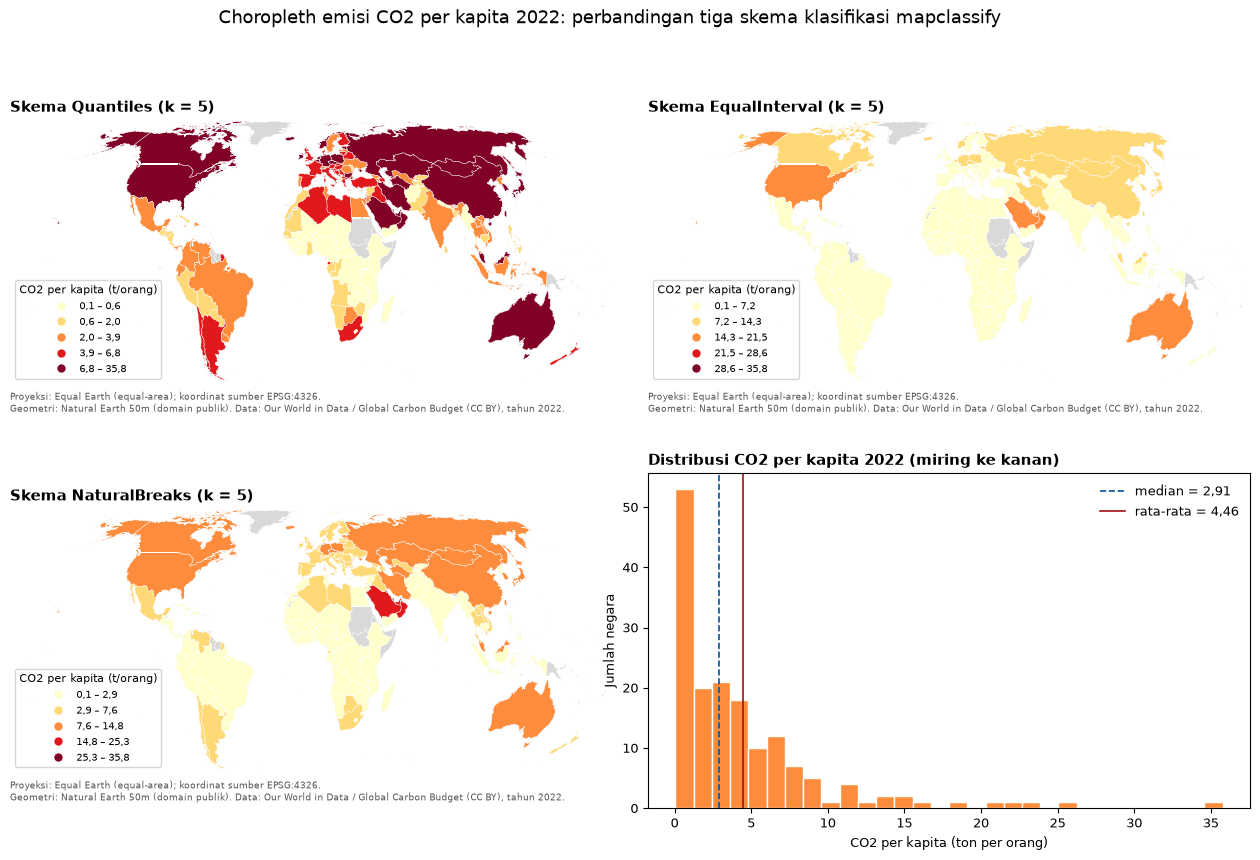

In [14]:
K = 5
y_pc = gdf["co2_per_capita"]
np.random.seed(42)  # NaturalBreaks memakai inisialisasi acak; seed dipasang agar hasil dapat direproduksi
skema_all = {
    "Quantiles": mc.Quantiles(y_pc, k=K),
    "EqualInterval": mc.EqualInterval(y_pc, k=K),
    "NaturalBreaks": mc.NaturalBreaks(y_pc, k=K, initial=100),
}
tabel_skema = pd.concat(
    {nama: pd.DataFrame({"batas atas (t/orang)": s.bins, "jumlah negara": s.counts}) for nama, s in skema_all.items()},
    axis=1,
)
display(tabel_skema.round(2))
print(f"Rata-rata = {y_pc.mean():.2f} t/orang; median = {y_pc.median():.2f} t/orang; skewness = {y_pc.skew():.2f}; "
      f"maksimum = {y_pc.max():.2f} t/orang")

fig = plt.figure(figsize=(16, 9.4))
posisi = {"Quantiles": 1, "EqualInterval": 2, "NaturalBreaks": 3}
for nama, pos in posisi.items():
    ax = fig.add_subplot(2, 2, pos, projection=ccrs.EqualEarth())
    s = skema_all[nama]
    peta_choropleth(ax, gdf, "co2_per_capita", s, "YlOrRd", f"Skema {nama} (k = {K})", "CO2 per kapita (t/orang)",
                    label_kelas(s, y_pc, 1))
ax_h = fig.add_subplot(2, 2, 4)
ax_h.hist(y_pc, bins=30, color="#fd8d3c", edgecolor="white")
ax_h.axvline(y_pc.median(), color="#08519c", ls="--", lw=1.2, label=f"median = {idn(y_pc.median(), 2)}")
ax_h.axvline(y_pc.mean(), color="#a50f15", ls="-", lw=1.2, label=f"rata-rata = {idn(y_pc.mean(), 2)}")
ax_h.set_title("Distribusi CO2 per kapita 2022 (miring ke kanan)", fontweight="bold", loc="left")
ax_h.set_xlabel("CO2 per kapita (ton per orang)")
ax_h.set_ylabel("Jumlah negara")
ax_h.legend(frameon=False)
fig.suptitle("Choropleth emisi CO2 per kapita 2022: perbandingan tiga skema klasifikasi mapclassify", y=0.96, fontsize=13)
fig.subplots_adjust(hspace=0.16, wspace=0.06)
simpan(fig, "02_choropleth_co2_per_kapita_tiga_skema.png")
plt.show()

In [15]:
SKEMA_TERPILIH = "Quantiles"
skema_co2 = skema_all[SKEMA_TERPILIH]
gdf["kelas_co2_per_kapita"] = skema_co2.yb
label_co2 = label_kelas(skema_co2, y_pc, 1)
print("Skema terpilih:", SKEMA_TERPILIH)
display(pd.DataFrame({"kelas": range(1, K + 1), "rentang (t/orang)": label_co2, "jumlah negara": skema_co2.counts}))

Skema terpilih: Quantiles


,kelas,rentang (t/orang),jumlah negara
0,1,"0,1 – 0,6",33
1,2,"0,6 – 2,0",32
2,3,"2,0 – 3,9",33
3,4,"3,9 – 6,8",32
4,5,"6,8 – 35,8",33


### Hasil dan interpretasi

Ketiga peta menghasilkan pola yang berbeda dari data yang sama. EqualInterval membagi rentang 0,06 sampai 35,77 t/orang menjadi lima selang selebar kira-kira 7,14 t/orang. Akibatnya 134 dari 163 negara (82,2 persen) masuk kelas pertama dan hanya Qatar yang berada pada kelas tertinggi. Peta menjadi hampir seragam kuning dan hanya menonjolkan segelintir negara. Quantiles menempatkan 33, 32, 33, 32, dan 33 negara pada kelas dengan batas atas 0,59; 1,96; 3,91; 6,84; dan 35,77 t/orang, sehingga perbedaan di antara mayoritas negara terlihat. NaturalBreaks menarik batas pada celah alami data, yaitu 2,91; 7,63; 14,83; 25,29; dan 35,77 t/orang, dengan 82, 54, 20, 6, dan 1 negara. Qatar terpisah sendirian dan enam negara dengan 14,83 sampai 25,29 t/orang (Bahrain, Kuwait, Trinidad dan Tobago, Uni Emirat Arab, Arab Saudi, Oman) terkelompok pada kelas keempat.

Penyebab perbedaan itu adalah kemiringan distribusi ke kanan, yang tampak pada histogram: skewness 2,60 dan rata-rata (4,46) lebih tinggi daripada median (2,91). Segelintir nilai ekstrem menarik nilai maksimum jauh dari mayoritas data. Skema berbasis lebar selang membuang hampir semua negara ke kelas terbawah. Skema berbasis peringkat menjaga jumlah negara per kelas tetap sama tetapi melebarkan rentang kelas teratas. NaturalBreaks mengikuti celah data sehingga ekor panjang menjadi kelas kecil, sementara kelas terbawah menampung 82 negara.

Skema yang dipilih adalah Quantiles dengan k = 5. Pertanyaan analisis menyangkut perbandingan relatif antarnegara, sehingga skema yang tetap membedakan seluruh peringkat lebih sesuai. Tidak ada kelas yang hampir kosong, dan skema yang sama dipakai pada peta GDP per kapita sehingga kuintil emisi dapat dibandingkan langsung dengan kuintil pendapatan. Kelemahannya perlu dicatat: kelas tertinggi (6,84 sampai 35,77 t/orang) menyatukan Tiongkok dan Qatar. Nilai ekstrem itu ditangani melalui tabel peringkat pada Tahap 7 dan skor relatif pada 4c. Pada peta Quantiles, kelas tertinggi tampak menutupi Amerika Utara, Rusia, Tiongkok, Timur Tengah, dan Australia, sedangkan kelas terendah tampak terkonsentrasi di Afrika.

### 4b. GDP per kapita

#### Tujuan

Memetakan pendapatan per kapita (gdp_per_kapita = gdp / population) sebagai pembanding emisi per kapita. Colormap sequential yang dipakai berbeda (GnBu) dan klasifikasinya memakai Quantiles dengan k = 5 agar tiap kelas berisi jumlah negara yang sebanding.

Tersimpan: outputs\figures\03_choropleth_gdp_per_kapita.png


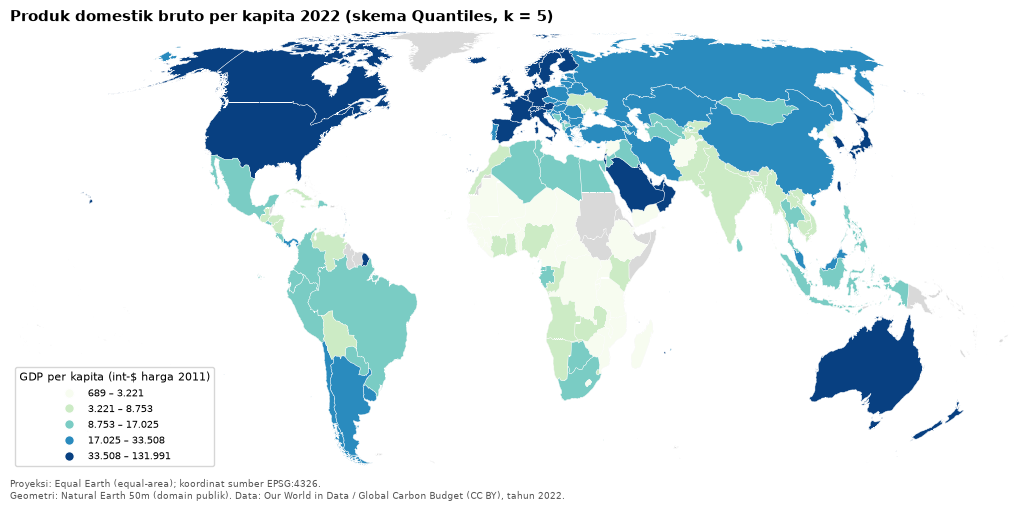

,rentang (int-$ per orang),jumlah negara
0,689 – 3.221,33
1,3.221 – 8.753,32
2,8.753 – 17.025,33
3,17.025 – 33.508,32
4,33.508 – 131.991,33


In [16]:
y_gdp = gdf["gdp_per_kapita"]
skema_gdp = mc.Quantiles(y_gdp, k=5)
label_gdp = label_kelas(skema_gdp, y_gdp, 0)
fig = plt.figure(figsize=(13, 6.4))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.EqualEarth())
peta_choropleth(ax, gdf, "gdp_per_kapita", skema_gdp, "GnBu", "Produk domestik bruto per kapita 2022 (skema Quantiles, k = 5)",
                "GDP per kapita (int-$ harga 2011)", label_gdp)
simpan(fig, "03_choropleth_gdp_per_kapita.png")
plt.show()
display(pd.DataFrame({"rentang (int-$ per orang)": label_gdp, "jumlah negara": skema_gdp.counts}))

### Hasil dan interpretasi

GDP per kapita pada 163 negara memiliki median 12.659 dan rata-rata 19.238 international-$ harga 2011, dengan skewness 2,01. Distribusinya miring ke kanan, tetapi lebih lemah daripada distribusi emisi. Batas atas kelas Quantiles adalah 3.221; 8.753; 17.025; 33.508; dan 131.991. Kelas tertinggi berisi 33 negara dan kelas terendah 33 negara. Nilai tertinggi dimiliki Qatar, 131.991 international-$ per orang.

Pada peta, Amerika Utara, Eropa barat dan utara, Australia, Selandia Baru, Jepang, Korea Selatan, serta negara Teluk tampak berada pada kelas tertinggi, sedangkan Afrika sub-Sahara tampak terkonsentrasi pada kelas pertama dan kedua. Pola luasnya mirip dengan peta emisi per kapita pada 4a, yaitu rendah di Afrika dan tinggi di Amerika Utara. Perbedaannya terdapat pada beberapa negara. Tiongkok (18.921) dan Rusia (25.632) berada pada kelas keempat GDP tetapi kelas tertinggi emisi. Sebaliknya Swedia (47.125 international-$, 3,56 t/orang) dan Swiss (63.623 international-$, 3,75 t/orang) sangat makmur tetapi emisi per kapitanya jauh di bawah negara dengan pendapatan serupa. Kemiripan pola menunjukkan keterkaitan, sedangkan negara yang menyimpang menunjukkan bahwa pendapatan bukan satu-satunya penentu.

### 4c. Skor emisi relatif dengan colormap diverging

#### Tujuan

Skor skor_co2_relatif = log10(co2_per_capita / median) bernilai nol bila emisi per kapita sama dengan median seluruh negara terpilih, positif bila lebih tinggi, dan negatif bila lebih rendah. Karena titik nol bermakna, dipakai colormap diverging (RdBu_r, merah di atas median dan biru di bawah median) dengan bin simetris terhadap nol melalui `mapclassify.UserDefined`. Batas atas kelas terakhir diatur agar mencakup nilai maksimum, sedangkan kelas pertama menampung seluruh nilai di bawah batas bawah.

Rentang skor_co2_relatif: minimum = -1.715, maksimum = 1.090, median = 0.000


Tersimpan: outputs\figures\04_choropleth_skor_co2_relatif_diverging.png


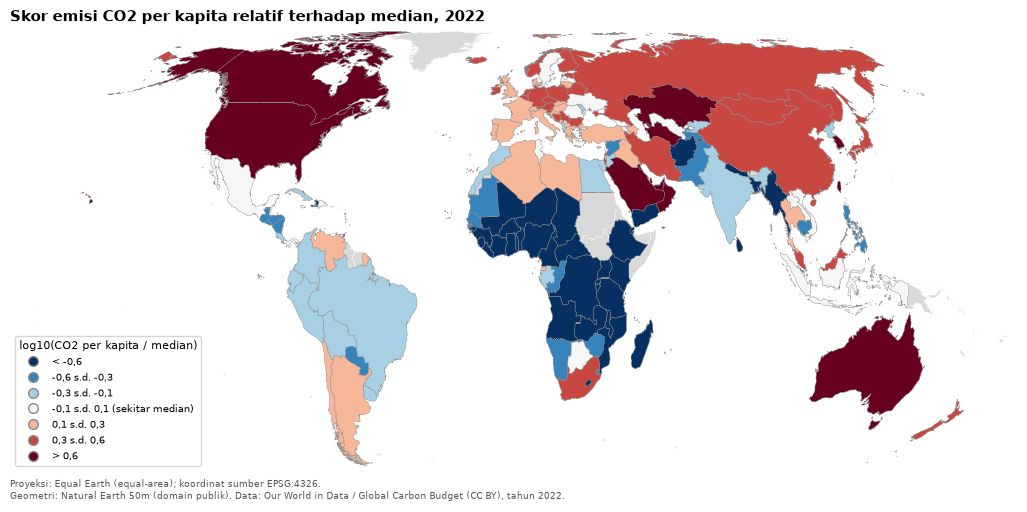

,batas skor,kelipatan median (10^skor)
0,-0.6,0.251
1,-0.3,0.501
2,-0.1,0.794
3,0.1,1.259
4,0.3,1.995
5,0.6,3.981


,kelas,jumlah negara
0,"< -0,6",39
1,"-0,6 s.d. -0,3",17
2,"-0,3 s.d. -0,1",17
3,"-0,1 s.d. 0,1 (sekitar median)",21
4,"0,1 s.d. 0,3",28
5,"0,3 s.d. 0,6",27
6,"> 0,6",14


,co2_per_capita,skor_co2_relatif,kelipatan_median
country,,,
United States,14.833,0.707,5.097
Russia,11.515,0.597,3.957
Indonesia,2.696,-0.033,0.926
India,1.979,-0.167,0.680
China,8.206,0.450,2.820
Brazil,2.285,-0.105,0.785


Negara pada kelas tertinggi (> 0,6): Qatar, Bahrain, Kuwait, Trinidad and Tobago, United Arab Emirates, Saudi Arabia, Oman, United States, Australia, Canada, Kazakhstan, Turkmenistan, South Korea, Taiwan
Negara pada kelas terendah (< -0,6), 8 terendah: Democratic Republic of Congo, Burundi, Central African Republic, Malawi, Niger, Liberia, Uganda, Rwanda


In [17]:
skor = gdf["skor_co2_relatif"]
print(f"Rentang skor_co2_relatif: minimum = {skor.min():.3f}, maksimum = {skor.max():.3f}, median = {skor.median():.3f}")
tepi = [-0.6, -0.3, -0.1, 0.1, 0.3, 0.6]                 # batas simetris terhadap nol
puncak = max(0.7, math.ceil(skor.max() * 10) / 10)       # batas atas kelas terakhir menutup nilai maksimum
bins_skor = tepi + [puncak]
skema_skor = mc.UserDefined(skor, bins_skor)
assert skema_skor.yb.min() == 0 and skema_skor.yb.max() == len(bins_skor) - 1 and skor.max() <= bins_skor[-1]
label_skor = ["< -0,6", "-0,6 s.d. -0,3", "-0,3 s.d. -0,1", "-0,1 s.d. 0,1 (sekitar median)", "0,1 s.d. 0,3", "0,3 s.d. 0,6", "> 0,6"]

fig = plt.figure(figsize=(13, 6.4))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.EqualEarth())
peta_choropleth(ax, gdf, "skor_co2_relatif", skema_skor, "RdBu_r", "Skor emisi CO2 per kapita relatif terhadap median, 2022",
                "log10(CO2 per kapita / median)", label_skor, edge="#8c8c8c")
simpan(fig, "04_choropleth_skor_co2_relatif_diverging.png")
plt.show()

arti = pd.DataFrame({"batas skor": tepi, "kelipatan median (10^skor)": [10 ** b for b in tepi]})
display(arti.round(3))
display(pd.DataFrame({"kelas": label_skor, "jumlah negara": skema_skor.counts}))
contoh = gdf[gdf["iso_code"].isin(["USA", "CHN", "RUS", "IND", "IDN", "BRA"])].set_index("country")
display(contoh[["co2_per_capita", "skor_co2_relatif"]].assign(kelipatan_median=lambda d: 10 ** d["skor_co2_relatif"]).round(3))
print("Negara pada kelas tertinggi (> 0,6):", ", ".join(gdf.loc[gdf["skor_co2_relatif"] > 0.6].sort_values("skor_co2_relatif", ascending=False)["country"]))
print("Negara pada kelas terendah (< -0,6), 8 terendah:", ", ".join(gdf.nsmallest(8, "skor_co2_relatif")["country"]))

### Hasil dan interpretasi

Skor menjadikan median sebagai titik tengah yang bermakna. Sebanyak 73 negara berada di bawah 0,794 kali median (skor kurang dari -0,1), 21 negara berada dalam rentang 0,794 sampai 1,259 kali median, dan 69 negara berada di atas 1,259 kali median. Pada skala logaritmik, dua kali lebih tinggi dan dua kali lebih rendah berjarak sama dari nol (sekitar ±0,301), sehingga warna merah dan biru dapat dibandingkan secara adil.

Kelas tertinggi (skor di atas 0,6, atau lebih dari 3,98 kali median, sekitar 11,6 t/orang) berisi 14 negara: Qatar, Bahrain, Kuwait, Trinidad dan Tobago, Uni Emirat Arab, Arab Saudi, Oman, Amerika Serikat, Australia, Kanada, Kazakhstan, Turkmenistan, Korea Selatan, dan Taiwan. Kelas terendah (di bawah 0,251 kali median, kurang dari sekitar 0,73 t/orang) berisi 39 negara. Delapan negara terendah adalah Republik Demokratik Kongo, Burundi, Republik Afrika Tengah, Malawi, Niger, Liberia, Uganda, dan Rwanda.

Skor negara terpilih adalah Amerika Serikat 0,707 (5,10 kali median), Rusia 0,597 (3,96 kali, tepat di bawah batas kelas tertinggi), Tiongkok 0,450 (2,82 kali), Indonesia -0,033 (0,926 kali, kelas sekitar median), Brasil -0,105 (0,785 kali), dan India -0,167 (0,680 kali). Peta ini menjawab pertanyaan pertama dari sisi lain: yang tinggi bukan hanya Qatar, melainkan 14 negara. Faktor yang menyatukan mereka, misalnya kekayaan sumber energi atau industri berat, hanya dapat diduga dan tidak diuji pada notebook ini. Median bersifat relatif terhadap 163 negara terpilih, sehingga skor tidak dapat ditafsirkan sebagai ambang batas keberlanjutan.

## Tahap 5. Multi-Dimensi dan Overlay

### 5a. Simbol proporsional: warna dan ukuran

#### Tujuan

Menampilkan dua variabel sekaligus pada satu peta dengan `gplt.pointplot`: warna titik menurut gdp_per_kapita (`hue`) dan ukuran titik menurut emisi total co2 (`scale`). Titik pusat tiap negara diambil dari `representative_point()`, yaitu titik yang dijamin berada di dalam poligon. Perlu ditegaskan bahwa titik ini hanyalah simbol proporsional untuk mewakili negara, bukan data titik asli seperti lokasi pembangkit listrik atau stasiun pengukuran. Diameter penanda dibuat sebanding dengan akar emisi sehingga luas penanda sebanding dengan emisi. Karena geoplot hanya menampilkan satu legenda variabel secara otomatis, legenda warna dibuat oleh geoplot dan legenda ukuran ditambahkan secara manual dengan fungsi skala yang sama.

In [18]:
# Titik pusat negara: representative_point() menjamin titik berada di dalam poligon (centroid bisa jatuh di luar).
titik = gdf.copy()
titik["geometry"] = gdf.geometry.representative_point()
di_dalam = titik.geometry.within(gdf.geometry)
print(f"Titik representatif berada di dalam poligon negaranya: {int(di_dalam.sum())} dari {len(titik)} negara")

DMAKS = 36.0  # diameter penanda terbesar (titik) untuk emisi total tertinggi
VMAKS = gdf["co2"].max()


def skala_ukuran(vmin, vmax):
    """Diameter penanda sebanding dengan akar emisi sehingga luas penanda sebanding dengan emisi total."""
    return lambda v: max(1.5, DMAKS * math.sqrt(v / vmax))


def legenda_ukuran(ax, nilai, loc="lower left", judul="Emisi total (Mt CO2)", jangkar=(1.01, 0.0)):
    pegangan = [Line2D([0], [0], marker="o", linestyle="None", markerfacecolor="none", markeredgecolor="black",
                       markersize=skala_ukuran(0, VMAKS)(v), label=f"{idn(v, 0)}") for v in nilai]
    return ax.legend(handles=pegangan, loc=loc, bbox_to_anchor=jangkar, title=judul, fontsize=7.5, title_fontsize=8,
                     labelspacing=1.6, borderpad=1.0, handlelength=5.0, handletextpad=1.0, frameon=True)

Titik representatif berada di dalam poligon negaranya: 163 dari 163 negara


Tersimpan: outputs\figures\05_pointplot_hue_gdp_scale_co2.png


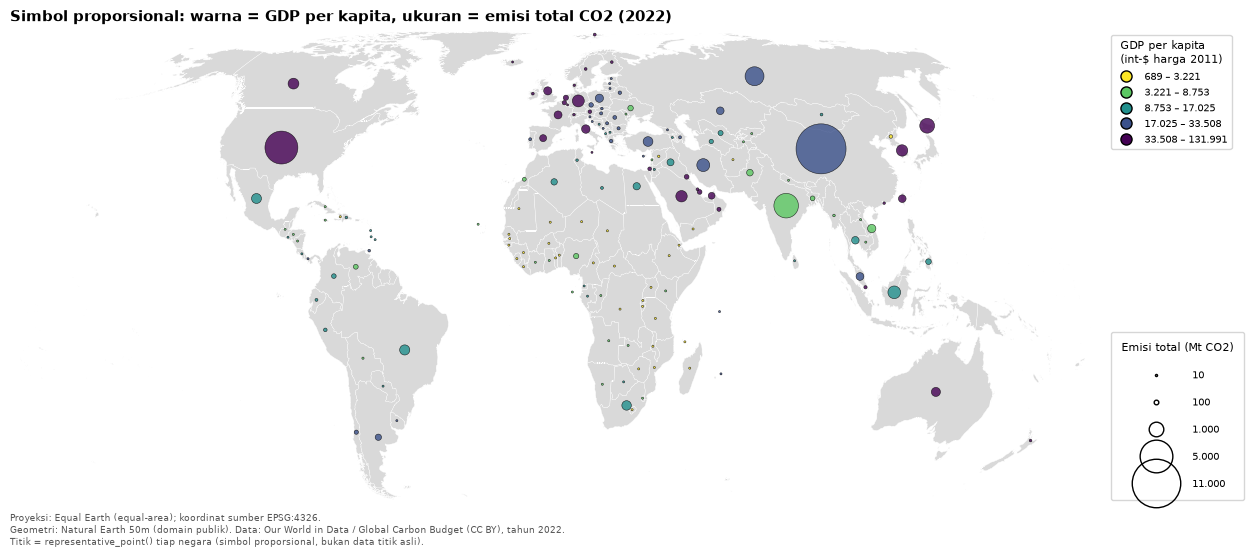

,jumlah,emisi_Mt,pangsa_emisi_dunia
kuintil_gdp,,,
1,33,263.82,0.70
2,32,4232.62,11.30
3,33,3882.69,10.36
4,32,16410.77,43.80
5,33,11579.19,30.90


In [19]:
skema_pt = mc.Quantiles(titik["gdp_per_kapita"], k=5)
label_pt = label_kelas(skema_pt, titik["gdp_per_kapita"], 0)
fig = plt.figure(figsize=(14, 7.2))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.EqualEarth())
latar(ax)
gplt.pointplot(titik, hue="gdp_per_kapita", scheme=skema_pt, cmap="viridis_r", scale="co2", scale_func=skala_ukuran,
               projection=gcrs.EqualEarth(), ax=ax, extent=EXT, edgecolor="black", linewidth=0.4, alpha=0.8,
               legend=True, legend_var="hue", legend_labels=label_pt,
               legend_kwargs={"loc": "upper left", "bbox_to_anchor": (1.01, 1.0), "fontsize": 7.5, "title": "GDP per kapita\n(int-$ harga 2011)",
                              "title_fontsize": 8, "markersize": 8, "frameon": True})
ax.add_artist(ax.get_legend())
legenda_ukuran(ax, [10, 100, 1000, 5000, 11000])
ax.set_title("Simbol proporsional: warna = GDP per kapita, ukuran = emisi total CO2 (2022)", fontweight="bold", loc="left")
catat(ax, CATATAN + "\nTitik = representative_point() tiap negara (simbol proporsional, bukan data titik asli).")
simpan(fig, "05_pointplot_hue_gdp_scale_co2.png")
plt.show()

titik["kuintil_gdp"] = skema_pt.yb + 1
display(titik.groupby("kuintil_gdp").agg(jumlah=("country", "size"), emisi_Mt=("co2", "sum"),
                                         pangsa_emisi_dunia=("share_global_co2", "sum")).round(2))

### Hasil dan interpretasi

Titik representatif berada di dalam poligon untuk 163 dari 163 negara. Luas lingkaran sebanding dengan emisi total, sehingga Tiongkok (11.695 Mt), Amerika Serikat (5.066 Mt), dan India (2.821 Mt) mendominasi, sedangkan sebagian besar negara Afrika tampak sebagai titik sangat kecil. Warna menunjukkan dimensi lain. Amerika Serikat (57.075 international-$ per orang), Jerman (46.496), Kanada (45.369), Korea Selatan (41.280), dan Jepang (38.197) berada pada kuintil GDP tertinggi, Tiongkok (18.921) pada kuintil keempat, dan India (7.350) pada kuintil kedua. Negara Teluk berwarna gelap tetapi berlingkaran kecil.

Ringkasan per kuintil GDP memperlihatkan bahwa emisi total terkonsentrasi pada kelompok yang lebih makmur. Kuintil pertama (33 negara) hanya menghasilkan 263,82 Mt atau 0,70 persen emisi dunia. Kuintil keempat (32 negara) menghasilkan 16.410,77 Mt atau 43,80 persen karena memuat Tiongkok, dan kuintil kelima (33 negara) menghasilkan 11.579,19 Mt atau 30,90 persen. Kedua kuintil teratas menghasilkan 74,70 persen emisi dunia. Pada peta ini warna dan ukuran bertukar peran: ukuran memperlihatkan kontribusi absolut, sedangkan warna memperlihatkan kemakmuran per orang.

Titik pada peta hanyalah simbol proporsional yang diletakkan di dalam poligon negara, bukan lokasi sumber emisi. Pada negara luas seperti Rusia, Kanada, dan Amerika Serikat, posisi titik tidak mencerminkan letak pusat industri.

### 5b. Overlay: choropleth, garis batas, dan titik 15 emitor terbesar

#### Tujuan

Menumpuk tiga lapisan: (1) choropleth emisi per kapita sebagai lapisan dasar, (2) garis batas seluruh negara, dan (3) titik proporsional untuk 15 negara dengan emisi total terbesar. Tumpukan ini dipakai untuk membandingkan emisi per kapita dengan emisi total.

Tersimpan: outputs\figures\06_overlay_per_kapita_dan_15_emitor_terbesar.png


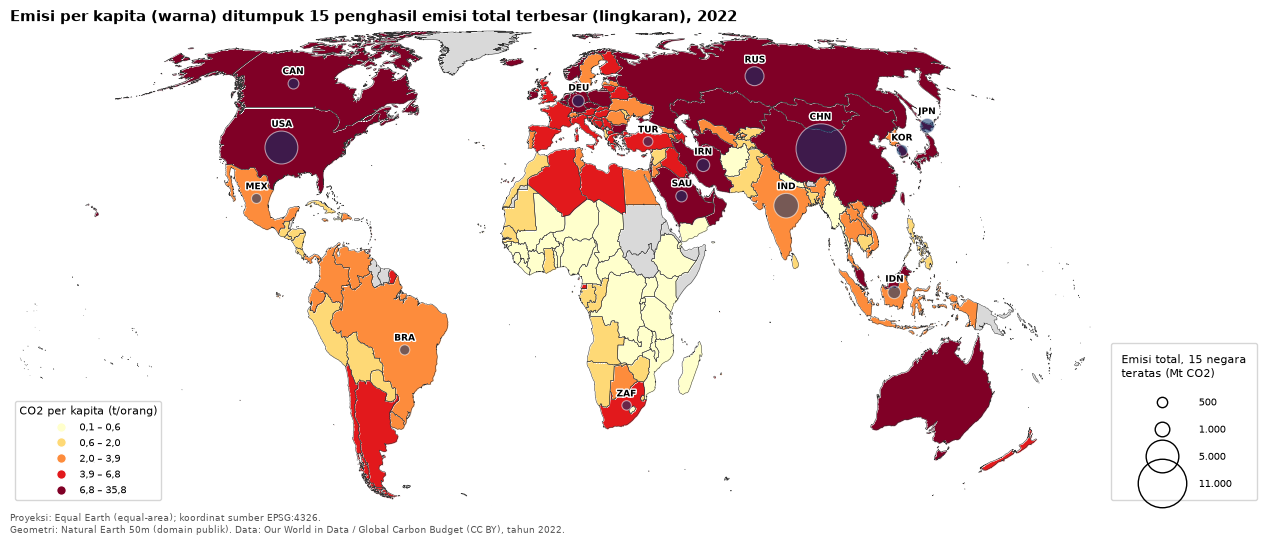

,iso_code,country,co2,share_global_co2,co2_per_capita,gdp_per_kapita,peringkat total,peringkat per kapita
0,CHN,China,11695.01,31.21,8.21,18921.14,1,24
1,USA,United States,5065.99,13.52,14.83,57075.34,2,8
2,IND,India,2821.41,7.53,1.98,7349.57,3,97
3,RUS,Russia,1676.35,4.47,11.51,25631.57,4,15
4,JPN,Japan,1027.56,2.74,8.22,38196.70,5,23
5,IRN,Iran,782.29,2.09,8.74,17561.82,6,22
6,IDN,Indonesia,751.75,2.01,2.70,12552.76,7,85
7,DEU,Germany,670.02,1.79,7.97,46495.28,8,27
8,SAU,Saudi Arabia,610.30,1.63,18.97,56685.82,9,6
9,KOR,South Korea,606.93,1.62,11.72,41279.54,10,13


Pangsa 15 emitor terbesar terhadap emisi dunia: 74.90%
Sebaran 15 emitor menurut kelas CO2 per kapita (1 = terendah, 5 = tertinggi): {3: 4, 4: 2, 5: 9}


In [20]:
top15 = titik.nlargest(15, "co2")
fig = plt.figure(figsize=(14, 7.4))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.EqualEarth())
# Lapisan 1 (dasar): choropleth CO2 per kapita
peta_choropleth(ax, gdf, "co2_per_capita", skema_co2, "YlOrRd", "", "CO2 per kapita (t/orang)", label_co2)
# Lapisan 2: garis batas seluruh negara
gplt.polyplot(dunia_bg, projection=gcrs.EqualEarth(), ax=ax, extent=EXT, facecolor="none", edgecolor="#333333",
              linewidth=0.35, zorder=3)
# Lapisan 3: 15 negara dengan emisi total terbesar (ukuran = emisi total)
gplt.pointplot(top15, scale="co2", scale_func=skala_ukuran, projection=gcrs.EqualEarth(), ax=ax, extent=EXT,
               color="#08306b", alpha=0.55, edgecolor="white", linewidth=0.8, zorder=4)
import matplotlib.patheffects as pe
for _, r in top15.iterrows():
    jari = skala_ukuran(0, VMAKS)(r["co2"]) / 2
    ax.annotate(r["iso_code"], xy=(r.geometry.x, r.geometry.y), xycoords=ccrs.Geodetic()._as_mpl_transform(ax),
                xytext=(0, jari + 1.5), textcoords="offset points", ha="center", va="bottom", fontsize=6.5, color="black",
                fontweight="bold", zorder=5, path_effects=[pe.withStroke(linewidth=2, foreground="white")])
ax.add_artist(ax.get_legend())
legenda_ukuran(ax, [500, 1000, 5000, 11000], judul="Emisi total, 15 negara\nteratas (Mt CO2)")
ax.set_title("Emisi per kapita (warna) ditumpuk 15 penghasil emisi total terbesar (lingkaran), 2022", fontweight="bold", loc="left")
simpan(fig, "06_overlay_per_kapita_dan_15_emitor_terbesar.png")
plt.show()

top15_tbl = top15[["iso_code", "country", "co2", "share_global_co2", "co2_per_capita", "gdp_per_kapita"]].copy()
top15_tbl["peringkat total"] = np.arange(1, 16)
gdf_rank = gdf["co2_per_capita"].rank(ascending=False, method="min").astype(int)
top15_tbl["peringkat per kapita"] = gdf_rank.loc[top15_tbl.index].values
display(top15_tbl.reset_index(drop=True).round(2))
print(f"Pangsa 15 emitor terbesar terhadap emisi dunia: {top15['share_global_co2'].sum():.2f}%")
kelas15 = gdf.loc[top15.index, "kelas_co2_per_kapita"].value_counts().sort_index()
print("Sebaran 15 emitor menurut kelas CO2 per kapita (1 = terendah, 5 = tertinggi):", {int(k) + 1: int(v) for k, v in kelas15.items()})

### Hasil dan interpretasi

Lima belas emitor terbesar menghasilkan 74,90 persen emisi dunia. Tumpukan lapisan memperlihatkan bahwa peringkat emisi total dan emisi per kapita tidak berjalan seiring. Sembilan dari 15 negara berada pada kelas per kapita tertinggi (6,84 sampai 35,77 t/orang): Tiongkok, Amerika Serikat, Rusia, Jepang, Iran, Jerman, Arab Saudi, Korea Selatan, dan Kanada. Dua negara berada pada kelas keempat (Turki 5,11 dan Afrika Selatan 6,79 t/orang), dan empat negara berada pada kelas ketiga (India 1,98; Brasil 2,29; Indonesia 2,70; Meksiko 3,61 t/orang).

Selisih peringkat memperjelas perbedaan itu. India berperingkat 3 pada emisi total tetapi 97 pada emisi per kapita dari 163 negara. Brasil berperingkat 12 dan 91, serta Indonesia 7 dan 85. Arab Saudi berperingkat 9 pada emisi total dan 6 pada emisi per kapita. Negara dengan emisi per kapita tertinggi pada 4a, Qatar, tidak termasuk 15 besar sehingga tidak tampak sebagai lingkaran sama sekali.

Interpretasinya, emisi total mencerminkan kontribusi absolut terhadap beban atmosfer dan banyak ditentukan oleh jumlah penduduk dan skala ekonomi. Emisi per kapita mencerminkan intensitas rata-rata per penduduk dan relevan untuk menilai keadilan beban antarnegara. Kedua ukuran mengarah pada prioritas yang berbeda, sehingga keduanya perlu dibaca bersama.

## Tahap 6. Teknik Lanjutan

Estimasi kepadatan kernel (*Kernel Density Estimation*, KDE) tidak dikerjakan karena dataset ini tidak memiliki data titik asli, melainkan atribut tingkat negara.

### 6a. Kartogram

#### Tujuan

Kartogram (*cartogram*) mengubah ukuran poligon menurut suatu variabel sehingga luas visual mencerminkan besaran data, bukan luas wilayah. Dengan `gplt.cartogram`, ukuran poligon diskalakan menurut emisi total (`scale=co2`) dan warna menurut emisi per kapita (`hue=co2_per_capita`). Hasilnya dibandingkan dengan peta biasa yang memakai skema klasifikasi dan warna yang sama.

Tersimpan: outputs\figures\07_kartogram_vs_peta_biasa.png


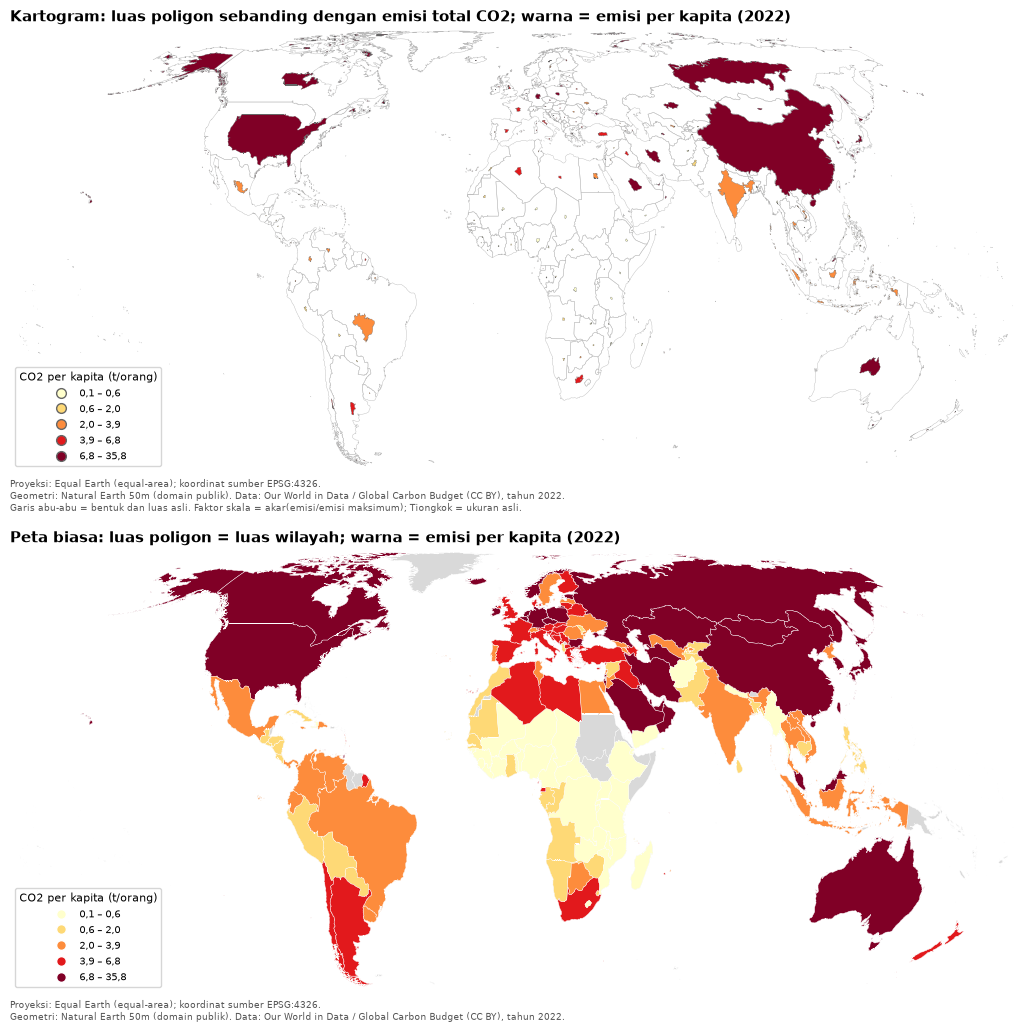

In [21]:
def skala_kartogram(vmin, vmax):
    """Faktor skala linear = akar(emisi / emisi maksimum), sehingga luas poligon kira-kira sebanding dengan emisi total."""
    return lambda v: max(0.06, math.sqrt(v / vmax))


# Poligon dipecah per bagian agar tiap bagian menyusut pada posisinya sendiri (geoplot menskalakan terhadap pusat kotak
# pembatas; tanpa pemecahan, negara lintas bujur seperti Rusia dan Amerika Serikat bergeser jauh dari posisi aslinya).
gdf_bagian = gdf.explode(index_parts=False).reset_index(drop=True)

fig = plt.figure(figsize=(14, 12.5))
ax1 = fig.add_subplot(2, 1, 1, projection=ccrs.EqualEarth())
gplt.polyplot(dunia_bg, projection=gcrs.EqualEarth(), ax=ax1, extent=EXT, facecolor="none", edgecolor="#bbbbbb", linewidth=0.3)
gplt.cartogram(gdf_bagian, scale="co2", scale_func=skala_kartogram, hue="co2_per_capita", scheme=skema_co2, cmap="YlOrRd",
               projection=gcrs.EqualEarth(), ax=ax1, extent=EXT, edgecolor="#666666", linewidth=0.2,
               legend=True, legend_var="hue", legend_labels=label_co2,
               legend_kwargs={"loc": "lower left", "fontsize": 7.5, "title": "CO2 per kapita (t/orang)",
                              "title_fontsize": 8, "markersize": 7, "frameon": True})
ax1.set_title("Kartogram: luas poligon sebanding dengan emisi total CO2; warna = emisi per kapita (2022)", fontweight="bold", loc="left")
catat(ax1, CATATAN + "\nGaris abu-abu = bentuk dan luas asli. Faktor skala = akar(emisi/emisi maksimum); Tiongkok = ukuran asli.")

ax2 = fig.add_subplot(2, 1, 2, projection=ccrs.EqualEarth())
peta_choropleth(ax2, gdf, "co2_per_capita", skema_co2, "YlOrRd", "Peta biasa: luas poligon = luas wilayah; warna = emisi per kapita (2022)",
                "CO2 per kapita (t/orang)", label_co2)
fig.subplots_adjust(hspace=0.18)
simpan(fig, "07_kartogram_vs_peta_biasa.png")
plt.show()

In [22]:
luas_wil = gdf.to_crs("EPSG:6933").area / 1e6
pangsa = pd.DataFrame({"negara": gdf["country"], "pangsa luas wilayah (%)": luas_wil / luas_wil.sum() * 100,
                       "pangsa emisi dunia (%)": gdf["share_global_co2"]})
pangsa["rasio emisi : luas"] = pangsa["pangsa emisi dunia (%)"] / pangsa["pangsa luas wilayah (%)"]
display(pangsa.nlargest(8, "pangsa emisi dunia (%)").round(2).reset_index(drop=True))
print("Contoh ekstrem rasio emisi : luas (negara dengan emisi total >= 10 Mt):")
display(pangsa[gdf["co2"] >= 10].sort_values("rasio emisi : luas", ascending=False).head(5).round(2).reset_index(drop=True))

,negara,pangsa luas wilayah (%),pangsa emisi dunia (%),rasio emisi : luas
0,China,7.33,31.21,4.26
1,United States,7.40,13.52,1.83
2,India,2.46,7.53,3.06
3,Russia,13.28,4.47,0.34
4,Japan,0.29,2.74,9.47
5,Iran,1.27,2.09,1.65
6,Indonesia,1.46,2.01,1.38
7,Germany,0.28,1.79,6.39


Contoh ekstrem rasio emisi : luas (negara dengan emisi total >= 10 Mt):


,negara,pangsa luas wilayah (%),pangsa emisi dunia (%),rasio emisi : luas
0,Singapore,0.00,0.13,356.11
1,Bahrain,0.00,0.10,244.76
2,Hong Kong,0.00,0.08,102.11
3,Qatar,0.01,0.28,31.94
4,Taiwan,0.03,0.73,26.03


### Hasil dan interpretasi

Kartogram mengubah luas poligon menurut emisi total. Tiongkok tampil dalam ukuran asli dan Amerika Serikat serta India menyusul, sedangkan sebagian besar Afrika dan Amerika Selatan menyusut hingga hampir tidak terlihat. Perbandingan dengan peta biasa di bawahnya menunjukkan perbedaan kesan yang tajam. Pada peta biasa, warna gelap menutupi bentang luas Kanada, Amerika Serikat, Rusia, Tiongkok, dan Australia. Pada kartogram, wilayah gelap yang bermakna secara total hanya segelintir negara.

Distorsi ukuran dapat dibaca dari perbandingan pangsa luas dan pangsa emisi. Rusia memiliki 13,28 persen luas wilayah 163 negara tetapi hanya 4,47 persen emisi dunia (rasio 0,34), sehingga mengecil tajam. Tiongkok memiliki 7,33 persen luas dan 31,21 persen emisi (rasio 4,26), India 2,46 dan 7,53 persen (3,06), Jepang 0,29 dan 2,74 persen (9,47), serta Jerman 0,28 dan 1,79 persen (6,39). Di antara negara dengan emisi minimal 10 Mt, rasio ekstrem dimiliki Singapura (356,11), Bahrain (244,76), Hong Kong (102,11), Qatar (31,94), dan Taiwan (26,03). Wilayah sekecil itu nyaris tidak terlihat pada peta biasa. Pangsa luas pada tabel dihitung terhadap total luas 163 negara, sedangkan pangsa emisi terhadap total dunia, sehingga rasio hanya cocok dipakai sebagai indikator relatif.

Kartogram ini memiliki keterbatasan. Faktor skala linear adalah akar dari emisi dibagi emisi maksimum (batas bawah 0,06), sehingga luas hasilnya hanya mendekati sebanding dengan emisi. Pengecilan dilakukan dalam derajat terhadap pusat tiap bagian poligon, sehingga poligon tidak lagi saling bersentuhan dan topologi antarnegara tidak terjaga. Hasilnya cocok untuk membandingkan besaran, bukan untuk membaca batas wilayah.

### 6b. Animasi spatio-temporal emisi per kapita

#### Tujuan

Mengamati perubahan pola spasial emisi per kapita pada tahun 1990, 1995, 2000, 2005, 2010, 2015, 2020, dan 2022 melalui animasi GIF yang dibuat dengan imageio. Agar antarframe dapat dibandingkan secara adil, dipakai himpunan negara yang tetap (hanya negara yang memiliki nilai pada kedelapan tahun), bin `UserDefined` yang sama pada seluruh frame, legenda yang konsisten, dan judul tahun pada tiap frame. Pewarnaan kelas dikendalikan secara eksplisit karena geoplot menormalkan warna menurut kelas yang teramati pada tiap frame, sehingga warna dapat bergeser bila ada kelas kosong. Pembuatan GIF dibungkus penanganan kesalahan agar kegagalan penyimpanan atau penayangan tidak menghentikan Run All.

In [23]:
TAHUN_ANIM = [1990, 1995, 2000, 2005, 2010, 2015, 2020, 2022]
hist = df_all[df_all["year"].isin(TAHUN_ANIM) & df_all["iso_code"].notna()]
hist = hist[~hist["iso_code"].str.startswith("OWID")]
piv = hist.pivot(index="iso_code", columns="year", values="co2_per_capita")
nama_negara = hist.drop_duplicates("iso_code").set_index("iso_code")["country"]

lengkap_semua = piv.dropna().index                    # punya nilai pada kedelapan tahun
tetap = [k for k in lengkap_semua if k in set(world["ADM0_A3"])]
print(f"Negara dengan nilai co2_per_capita pada kedelapan tahun: {len(lengkap_semua)}; "
      f"dengan geometri Natural Earth (himpunan tetap animasi): {len(tetap)}")
print("Tidak memiliki geometri:", sorted(set(lengkap_semua) - set(tetap)))
piv_tetap = piv.loc[tetap]

BATAS_ANIM = [1, 2, 5, 10, 20]
puncak_anim = float(math.ceil(piv_tetap.to_numpy().max() / 10) * 10)
BINS_ANIM = BATAS_ANIM + [puncak_anim]
LABEL_ANIM = ["≤ 1", "1 – 2", "2 – 5", "5 – 10", "10 – 20", f"> 20 (maks. {idn(piv_tetap.to_numpy().max(), 1)})"]
WARNA_ANIM = plt.get_cmap("YlOrRd")(np.linspace(0.12, 1.0, len(BINS_ANIM)))
print("Bin UserDefined yang sama untuk semua frame:", BINS_ANIM)

rows = []
for t in TAHUN_ANIM:
    s = mc.UserDefined(piv_tetap[t], BINS_ANIM)
    rows.append({"tahun": t, "median": piv_tetap[t].median(), "rata-rata": piv_tetap[t].mean(),
                 "maks": piv_tetap[t].max(), "negara maks": nama_negara[piv_tetap[t].idxmax()],
                 **{f"kelas {i+1}": int(c) for i, c in enumerate(s.counts)}})
tabel_anim = pd.DataFrame(rows).set_index("tahun")
display(tabel_anim.round(2))

Negara dengan nilai co2_per_capita pada kedelapan tahun: 213; dengan geometri Natural Earth (himpunan tetap animasi): 205
Tidak memiliki geometri: ['BES', 'GLP', 'GUF', 'MTQ', 'MYT', 'PSE', 'REU', 'SSD']
Bin UserDefined yang sama untuk semua frame: [1, 2, 5, 10, 20, 70.0]


,median,rata-rata,maks,negara maks,kelas 1,kelas 2,kelas 3,kelas 4,kelas 5,kelas 6
tahun,,,,,,,,,,
1990,2.63,5.07,30.94,Luxembourg,72,21,37,43,23,9
1995,2.55,4.97,60.97,Qatar,70,26,39,41,20,9
2000,2.88,5.19,56.85,Qatar,69,22,39,44,23,8
2005,3.10,5.46,54.69,Qatar,61,28,39,43,24,10
2010,2.94,5.36,40.07,Qatar,59,23,46,44,24,9
2015,3.01,5.10,40.04,Curacao,56,24,54,45,18,8
2020,3.09,4.55,33.79,Qatar,53,30,62,39,15,6
2022,3.24,4.72,35.77,Qatar,50,28,59,45,17,6


GIF tersimpan: outputs\figures\08_animasi_co2_per_kapita_1990_2022.gif | 8 frame | durasi per frame (ms): [1200, 1200, 1200, 1200, 1200, 1200, 1200, 3000] | 0.33 MB


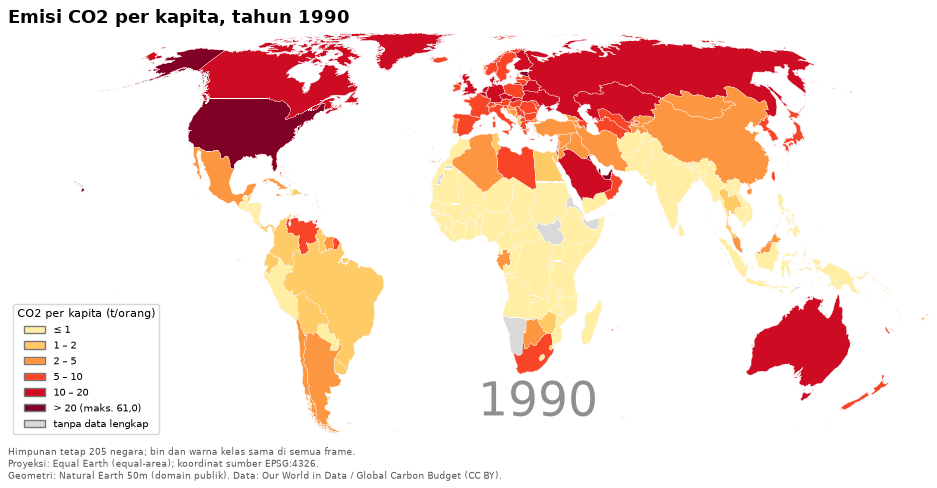

In [24]:
geo_anim = world[world["ADM0_A3"].isin(tetap)][["ADM0_A3", "NAME", "geometry"]].reset_index(drop=True)
GIF_PATH = FIG / "08_animasi_co2_per_kapita_1990_2022.gif"
PANEL_PATH = FIG / "08_animasi_co2_per_kapita_panel.png"


def gambar_frame(tahun):
    d = geo_anim.merge(piv_tetap[[tahun]].rename(columns={tahun: "nilai"}), left_on="ADM0_A3", right_index=True)
    d["kelas"] = mc.UserDefined(d["nilai"], BINS_ANIM).yb          # kelas dari bin yang sama di semua frame
    fig = plt.figure(figsize=(12, 6.3), dpi=100)
    ax = fig.add_subplot(1, 1, 1, projection=ccrs.EqualEarth())
    latar(ax)
    gplt.choropleth(d, hue="kelas", cmap=ListedColormap(WARNA_ANIM), norm=BoundaryNorm(np.arange(-0.5, len(BINS_ANIM), 1), len(BINS_ANIM)),
                    projection=gcrs.EqualEarth(), ax=ax, extent=EXT, edgecolor="white", linewidth=0.25)
    pegangan = [Patch(facecolor=w, edgecolor="#777777", label=l) for w, l in zip(WARNA_ANIM, LABEL_ANIM)]
    pegangan.append(Patch(facecolor="#d9d9d9", edgecolor="#777777", label="tanpa data lengkap"))
    ax.legend(handles=pegangan, loc="lower left", title="CO2 per kapita (t/orang)", fontsize=7.5, title_fontsize=8, frameon=True)
    ax.set_title(f"Emisi CO2 per kapita, tahun {tahun}", fontweight="bold", loc="left", fontsize=13)
    ax.text(0.57, 0.03, str(tahun), transform=ax.transAxes, ha="center", va="bottom", fontsize=34, color="#444444", alpha=0.6)
    catat(ax, f"Himpunan tetap {len(tetap)} negara; bin dan warna kelas sama di semua frame.\n" + CATATAN.replace(", tahun 2022", ""))
    fig.canvas.draw()
    frame = np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()
    plt.close(fig)
    return frame


try:
    frames = [gambar_frame(t) for t in TAHUN_ANIM]
    assert len({f.shape for f in frames}) == 1, "ukuran frame tidak seragam"
    # pangkas margin putih dengan kotak yang sama untuk semua frame (ukuran frame tetap seragam)
    tidak_putih = np.any([(f < 250).any(axis=2) for f in frames], axis=0)
    ys, xs = np.where(tidak_putih)
    y0, y1, x0, x1 = max(ys.min() - 8, 0), ys.max() + 8, max(xs.min() - 8, 0), xs.max() + 8
    frames = [f[y0:y1, x0:x1] for f in frames]
    durasi_ms = [1200] * (len(frames) - 1) + [3000]
    iio.mimsave(GIF_PATH, frames, duration=durasi_ms, loop=0)

    # panel statis berisi seluruh frame (cadangan bila GIF tidak dapat diputar pada penampil tertentu)
    fig_p, axs = plt.subplots(4, 2, figsize=(14, 11.5))
    for a, f, t in zip(axs.ravel(), frames, TAHUN_ANIM):
        a.imshow(f)
        a.axis("off")
    fig_p.suptitle("Panel statis frame animasi CO2 per kapita 1990 sampai 2022 (bin dan warna identik)", y=0.995)
    fig_p.tight_layout(h_pad=0.4, w_pad=0.4)
    fig_p.savefig(PANEL_PATH, dpi=200, bbox_inches="tight", facecolor="white")
    plt.close(fig_p)

    from PIL import Image as PILImage
    with PILImage.open(GIF_PATH) as g:
        durasi_baca = []
        for i in range(g.n_frames):
            g.seek(i)
            durasi_baca.append(g.info.get("duration"))
        print(f"GIF tersimpan: {GIF_PATH.relative_to(ROOT)} | {g.n_frames} frame | durasi per frame (ms): {durasi_baca} | "
              f"{GIF_PATH.stat().st_size / 1e6:.2f} MB")
    display(Image(filename=str(GIF_PATH)))
except Exception as galat:  # pembuatan GIF tidak boleh menggagalkan Run All
    print(f"Pembuatan GIF gagal ({type(galat).__name__}: {galat}). Tabel ringkasan di atas tetap dapat dipakai untuk interpretasi.")

In [25]:
a, b = piv_tetap[1990], piv_tetap[2022]
perubahan = pd.DataFrame({"negara": [nama_negara[k] for k in piv_tetap.index], "1990": a.values, "2022": b.values,
                          "selisih (t/orang)": (b - a).values}, index=piv_tetap.index)
print("Kenaikan terbesar CO2 per kapita 1990 ke 2022:")
display(perubahan.nlargest(6, "selisih (t/orang)").round(2))
print("Penurunan terbesar:")
display(perubahan.nsmallest(6, "selisih (t/orang)").round(2))
print(f"Jumlah negara yang naik: {(perubahan['selisih (t/orang)'] > 0).sum()}, turun: {(perubahan['selisih (t/orang)'] < 0).sum()} "
      f"(dari {len(perubahan)})")
for kode in ["CHN", "IND", "IDN", "USA"]:
    print(f"  {nama_negara[kode]:15s}: {piv_tetap.loc[kode, 1990]:6.2f} (1990) -> {piv_tetap.loc[kode, 2022]:6.2f} (2022) t/orang; "
          f"rasio 2022/1990 = {piv_tetap.loc[kode, 2022] / piv_tetap.loc[kode, 1990]:.2f}; perubahan {100 * (piv_tetap.loc[kode, 2022] / piv_tetap.loc[kode, 1990] - 1):+.1f}%")

Kenaikan terbesar CO2 per kapita 1990 ke 2022:


,negara,1990,2022,selisih (t/orang)
iso_code,,,,
OMN,Oman,6.42,16.49,10.07
QAT,Qatar,25.96,35.77,9.81
NCL,New Caledonia,8.82,17.72,8.90
TTO,Trinidad and Tobago,13.56,22.20,8.63
BRN,Brunei,19.68,27.32,7.64
CHN,China,2.16,8.21,6.05


Penurunan terbesar:


,negara,1990,2022,selisih (t/orang)
iso_code,,,,
CUW,Curacao,30.72,8.30,-22.42
LUX,Luxembourg,30.94,11.13,-19.82
EST,Estonia,23.50,8.87,-14.64
UKR,Ukraine,13.57,3.48,-10.09
NRU,Nauru,12.92,4.96,-7.96
CZE,Czechia,15.95,8.91,-7.04


Jumlah negara yang naik: 124, turun: 81 (dari 205)
  China          :   2.16 (1990) ->   8.21 (2022) t/orang; rasio 2022/1990 = 3.80; perubahan +280.4%
  India          :   0.68 (1990) ->   1.98 (2022) t/orang; rasio 2022/1990 = 2.93; perubahan +193.1%
  Indonesia      :   0.86 (1990) ->   2.70 (2022) t/orang; rasio 2022/1990 = 3.14; perubahan +214.4%
  United States  :  20.25 (1990) ->  14.83 (2022) t/orang; rasio 2022/1990 = 0.73; perubahan -26.7%


### Hasil dan interpretasi

Animasi memakai himpunan tetap 205 negara, yaitu negara yang memiliki nilai pada kedelapan tahun dan geometri Natural Earth. Dari 213 negara bernilai lengkap, delapan tidak memiliki geometri yang cocok (BES, GLP, GUF, MTQ, MYT, PSE, REU, SSD). Bin UserDefined yang sama adalah 1, 2, 5, 10, 20, dan batas atas 70 t/orang (nilai maksimum seluruh frame 60,97 t/orang, Qatar pada 1995). GIF terdiri dari delapan frame dengan 1,2 detik per frame dan 3 detik pada frame terakhir. Panel statis berisi frame yang sama tersimpan sebagai cadangan.

Median emisi per kapita himpunan tetap bergerak dari 2,63 t/orang (1990) ke 2,55 (1995), 2,88 (2000), 3,10 (2005), 2,94 (2010), 3,01 (2015), 3,09 (2020), dan 3,24 (2022). Rata-ratanya justru turun dari 5,07 menjadi 4,72 t/orang setelah mencapai 5,46 pada 2005. Perubahan ini terbaca pada jumlah negara per kelas. Kelas di bawah atau sama dengan 1 t/orang menyusut dari 72 menjadi 50 negara, kelas 2 sampai 5 t/orang membesar dari 37 menjadi 59 negara, dan kelas di atas 20 t/orang menyusut dari 9 menjadi 6 negara. Pola ini menunjukkan pergeseran negara berpenghasilan rendah ke kelas yang lebih tinggi sambil sebagian negara dengan emisi per kapita sangat tinggi menurun. Sebanyak 124 dari 205 negara mengalami kenaikan dan 81 negara penurunan antara 1990 dan 2022.

Pada negara besar, Tiongkok naik dari 2,16 ke 8,21 t/orang (3,80 kali) dan berpindah dari kelas 2 sampai 5 ke kelas 5 sampai 10. India naik dari 0,68 ke 1,98 t/orang (2,93 kali) dan Indonesia dari 0,86 ke 2,70 t/orang (3,14 kali). Amerika Serikat turun dari 20,25 ke 14,83 t/orang (-26,7 persen) dan, menurut panel statis, keluar dari kelas di atas 20 t/orang antara 2005 dan 2010. Kenaikan terbesar terjadi di Oman (+10,07 t/orang), Qatar (+9,81), New Caledonia (+8,90), Trinidad dan Tobago (+8,63), dan Brunei (+7,64). Penurunan terbesar terjadi di Curacao (-22,42), Luxembourg (-19,82), Estonia (-14,64), dan Ukraina (-10,09). Qatar tetap tertinggi pada 2022 meski turun dari puncak 60,97 t/orang pada 1995. Penyebab penurunan pada Luxembourg, Estonia, dan Ukraina, misalnya perubahan struktur ekonomi atau pertumbuhan penduduk, hanya dapat diduga dan tidak dapat dibuktikan dengan data pada notebook ini. Himpunan tetap juga memuat wilayah non-berdaulat berpenduduk kecil, seperti Curacao dan New Caledonia, yang nilainya mudah berubah besar.

## Tahap 7. Insight, Kesimpulan, dan Rekomendasi

### Tujuan

Tahap ini merangkum temuan menjadi insight berangka yang menjawab tiga pertanyaan analisis, menurunkan kesimpulan serta rekomendasi tindak lanjut, dan menyatakan keterbatasan analisis. Seluruh angka disajikan lewat tabel yang dihitung dari data pada sel di bawah.

In [26]:
kol = ["country", "co2", "share_global_co2", "co2_per_capita", "population"]
top10_total = gdf.nlargest(10, "co2")[kol].reset_index(drop=True)
top10_total.insert(0, "peringkat", range(1, 11))
top10_total["pangsa kumulatif (%)"] = top10_total["share_global_co2"].cumsum()
display(top10_total.round(2))

top10_pc = gdf.nlargest(10, "co2_per_capita")[["country", "co2_per_capita", "co2", "gdp_per_kapita", "population"]].reset_index(drop=True)
top10_pc.insert(0, "peringkat", range(1, 11))
display(top10_pc.round(2))

urut = gdf.sort_values("share_global_co2", ascending=False).reset_index(drop=True)
urut["kumulatif"] = urut["share_global_co2"].cumsum()
n50 = int((urut["kumulatif"] < 50).sum() + 1)
n80 = int((urut["kumulatif"] < 80).sum() + 1)
pangsa_top10 = top10_total["share_global_co2"].sum()
pangsa_pop_top10 = gdf.nlargest(10, "co2")["population"].sum() / gdf["population"].sum() * 100
pangsa_pop_top10_dunia = gdf.nlargest(10, "co2")["population"].sum()
print(f"Pangsa kumulatif 10 penghasil terbesar: {pangsa_top10:.2f}% emisi dunia")
print(f"Pangsa penduduk 10 penghasil terbesar terhadap penduduk {len(gdf)} negara terpilih: {pangsa_pop_top10:.2f}%")
print(f"Jumlah negara yang diperlukan untuk mencapai 50% emisi dunia: {n50}; 80%: {n80}")
print(f"Total pangsa emisi dunia yang tercakup oleh {len(gdf)} negara terpilih: {gdf['share_global_co2'].sum():.2f}%")
rata_pk = gdf["co2"].sum() / gdf["population"].sum() * 1e6
q = top10_pc.iloc[0]
print(f"{q['country']}: {q['co2_per_capita']:.2f} t/orang = {q['co2_per_capita'] / MEDIAN_CO2PC:.1f} kali median dan {q['co2_per_capita'] / rata_pk:.1f} kali rata-rata tertimbang ({rata_pk:.2f})")
print(f"Pangsa emisi dunia 10 negara dengan emisi per kapita tertinggi: {gdf.nlargest(10, 'co2_per_capita')['share_global_co2'].sum():.2f}%")
print(f"Jumlah negara dengan emisi per kapita di atas rata-rata tertimbang: {(gdf['co2_per_capita'] >= rata_pk).sum()} dari {len(gdf)}")

,peringkat,country,co2,share_global_co2,co2_per_capita,population,pangsa kumulatif (%)
0,1,China,11695.01,31.21,8.21,1.425180e+09,31.21
1,2,United States,5065.99,13.52,14.83,3.415340e+08,44.73
2,3,India,2821.41,7.53,1.98,1.425423e+09,52.26
3,4,Russia,1676.35,4.47,11.51,1.455799e+08,56.73
4,5,Japan,1027.56,2.74,8.22,1.249976e+08,59.48
5,6,Iran,782.29,2.09,8.74,8.952425e+07,61.56
6,7,Indonesia,751.75,2.01,2.70,2.788305e+08,63.57
7,8,Germany,670.02,1.79,7.97,8.408623e+07,65.36
8,9,Saudi Arabia,610.30,1.63,18.97,3.217535e+07,66.99
9,10,South Korea,606.93,1.62,11.72,5.178252e+07,68.61


,peringkat,country,co2_per_capita,co2,gdp_per_kapita,population
0,1,Qatar,35.77,103.47,131990.53,2892466.0
1,2,Bahrain,25.29,38.78,38324.94,1533460.0
2,3,Kuwait,22.84,104.82,47709.02,4589514.0
3,4,Trinidad and Tobago,22.20,33.21,25077.08,1495923.0
4,5,United Arab Emirates,20.81,213.15,76127.23,10242085.0
5,6,Saudi Arabia,18.97,610.30,56685.82,32175351.0
6,7,Oman,16.49,78.00,37493.96,4730229.0
7,8,United States,14.83,5065.99,57075.34,341534041.0
8,9,Australia,14.80,387.75,51305.37,26200987.0
9,10,Canada,14.06,545.73,45369.36,38821259.0


Pangsa kumulatif 10 penghasil terbesar: 68.61% emisi dunia
Pangsa penduduk 10 penghasil terbesar terhadap penduduk 163 negara terpilih: 50.59%
Jumlah negara yang diperlukan untuk mencapai 50% emisi dunia: 3; 80%: 21
Total pangsa emisi dunia yang tercakup oleh 163 negara terpilih: 97.06%
Qatar: 35.77 t/orang = 12.3 kali median dan 7.8 kali rata-rata tertimbang (4.60)
Pangsa emisi dunia 10 negara dengan emisi per kapita tertinggi: 19.16%
Jumlah negara dengan emisi per kapita di atas rata-rata tertimbang: 53 dari 163


Korelasi Spearman (peringkat): 0.896
Korelasi Pearson pada log10-log10: 0.911; R kuadrat = 0.830; lereng elastisitas = 1.048


,jumlah,gdp_pk_median,co2_pk_median,pangsa_emisi_dunia
kuartil_pendapatan,,,,
K1 (terendah),41,1768.04,0.31,1.00
K2,41,8192.83,1.94,16.10
K3,40,18706.56,4.12,47.55
K4 (tertinggi),41,42062.04,7.48,32.41


Tersimpan: outputs\figures\09_sebar_co2_vs_gdp_per_kapita.png


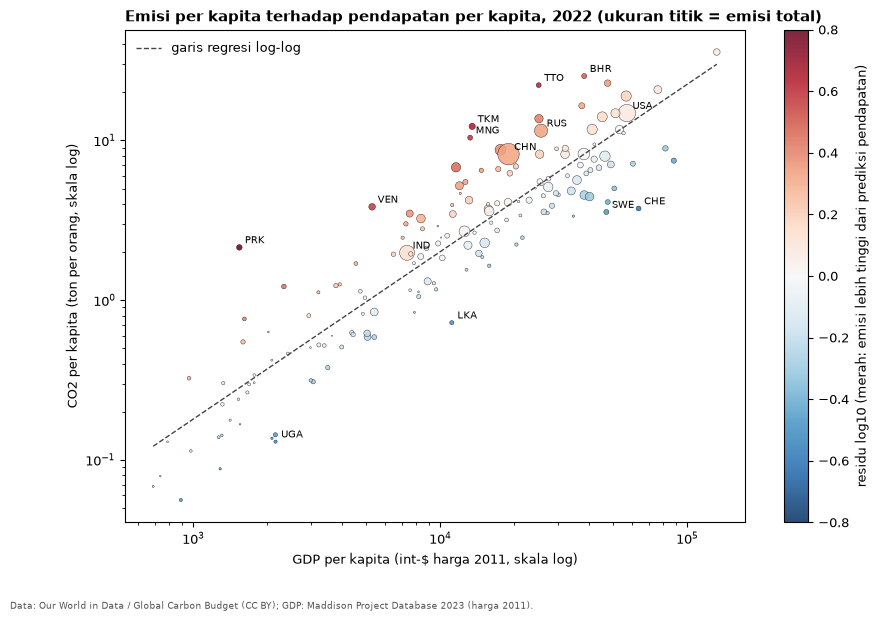

Emisi per kapita paling melampaui prediksi dari pendapatan:


,country,gdp_per_kapita,co2_per_capita,residu_log,kali dari prediksi
0,North Korea,1537.81,2.14,0.88,7.58
1,Turkmenistan,13485.52,12.25,0.65,4.46
2,Trinidad and Tobago,25077.08,22.20,0.62,4.22
3,Mongolia,13233.69,10.41,0.59,3.86
4,Venezuela,5305.43,3.84,0.57,3.72


Emisi per kapita paling di bawah prediksi dari pendapatan:


,country,gdp_per_kapita,co2_per_capita,residu_log,kali dari prediksi
0,Switzerland,63623.01,3.75,-0.57,0.27
1,Sri Lanka,11156.08,0.72,-0.49,0.32
2,Uganda,2155.77,0.13,-0.49,0.32
3,Sweden,47124.89,3.56,-0.46,0.35
4,Democratic Republic of Congo,891.77,0.06,-0.45,0.35


In [27]:
x, yv = gdf["gdp_per_kapita"], gdf["co2_per_capita"]
rho = x.corr(yv, method="spearman")
r_log = np.log10(x).corr(np.log10(yv))
lereng, intersep = np.polyfit(np.log10(x), np.log10(yv), 1)
gdf["residu_log"] = np.log10(yv) - (intersep + lereng * np.log10(x))
r2 = r_log ** 2
print(f"Korelasi Spearman (peringkat): {rho:.3f}")
print(f"Korelasi Pearson pada log10-log10: {r_log:.3f}; R kuadrat = {r2:.3f}; lereng elastisitas = {lereng:.3f}")

gdf["kuartil_pendapatan"] = pd.qcut(x, 4, labels=["K1 (terendah)", "K2", "K3", "K4 (tertinggi)"])
tabel_kuartil = gdf.groupby("kuartil_pendapatan", observed=True).agg(
    jumlah=("country", "size"), gdp_pk_median=("gdp_per_kapita", "median"),
    co2_pk_median=("co2_per_capita", "median"), pangsa_emisi_dunia=("share_global_co2", "sum")).round(2)
display(tabel_kuartil)

fig, ax = plt.subplots(figsize=(10, 6.4))
sc = ax.scatter(x, yv, s=np.sqrt(gdf["co2"]) * 2.2, c=gdf["residu_log"], cmap="RdBu_r", vmin=-0.8, vmax=0.8,
                edgecolor="black", linewidth=0.3, alpha=0.85)
gx = np.linspace(x.min(), x.max(), 100)
ax.plot(gx, 10 ** (intersep + lereng * np.log10(gx)), color="#444444", ls="--", lw=1, label="garis regresi log-log")
ax.set_xscale("log")
ax.set_yscale("log")
for _, r in pd.concat([gdf.nlargest(6, "residu_log"), gdf.nsmallest(4, "residu_log"), gdf.nlargest(4, "co2")]).drop_duplicates("iso_code").iterrows():
    ax.annotate(r["iso_code"], (r["gdp_per_kapita"], r["co2_per_capita"]), xytext=(4, 3), textcoords="offset points", fontsize=7)
ax.set_xlabel("GDP per kapita (int-$ harga 2011, skala log)")
ax.set_ylabel("CO2 per kapita (ton per orang, skala log)")
ax.set_title("Emisi per kapita terhadap pendapatan per kapita, 2022 (ukuran titik = emisi total)", fontweight="bold", loc="left")
fig.colorbar(sc, ax=ax, label="residu log10 (merah: emisi lebih tinggi dari prediksi pendapatan)")
ax.legend(frameon=False, loc="upper left")
fig.text(0.01, -0.025, "Data: Our World in Data / Global Carbon Budget (CC BY); GDP: Maddison Project Database 2023 (harga 2011).",
         fontsize=6.5, color="#555555")
simpan(fig, "09_sebar_co2_vs_gdp_per_kapita.png")
plt.show()

res = gdf[["country", "gdp_per_kapita", "co2_per_capita", "residu_log"]].copy()
res["kali dari prediksi"] = 10 ** res["residu_log"]
print("Emisi per kapita paling melampaui prediksi dari pendapatan:")
display(res.nlargest(5, "residu_log").round(2).reset_index(drop=True))
print("Emisi per kapita paling di bawah prediksi dari pendapatan:")
display(res.nsmallest(5, "residu_log").round(2).reset_index(drop=True))

In [28]:
rata_pk = gdf["co2"].sum() / gdf["population"].sum() * 1e6   # rata-rata tertimbang penduduk (t/orang)
print(f"Rata-rata CO2 per kapita tertimbang penduduk ({len(gdf)} negara): {rata_pk:.2f} t/orang; median tanpa bobot: {MEDIAN_CO2PC:.2f}")
iso_top15 = set(top15["iso_code"])
gdf["emitor_besar"] = gdf["iso_code"].isin(iso_top15)
gdf["pk_tinggi"] = gdf["co2_per_capita"] >= rata_pk
kondisi = [gdf.emitor_besar & gdf.pk_tinggi, gdf.emitor_besar & ~gdf.pk_tinggi, ~gdf.emitor_besar & gdf.pk_tinggi]
nama_k = ["A. Emitor besar dan per kapita tinggi", "B. Emitor besar dan per kapita rendah", "C. Emitor kecil dan per kapita tinggi"]
gdf["kelompok"] = np.select(kondisi, nama_k, default="D. Emitor kecil dan per kapita rendah")
tabel_kel = gdf.groupby("kelompok").agg(jumlah=("country", "size"), pangsa_emisi_dunia=("share_global_co2", "sum"),
                                         pangsa_penduduk=("population", lambda s: s.sum() / gdf["population"].sum() * 100),
                                         anggota=("iso_code", lambda s: ", ".join(s) if len(s) <= 18 else f"{len(s)} negara"))
display(tabel_kel.drop(columns="anggota").round(2))
for k in nama_k:
    print(k, "->", ", ".join(gdf.loc[gdf["kelompok"] == k].sort_values("co2", ascending=False)["country"].head(15)))

kelompok_c = gdf[gdf["kelompok"] == nama_k[2]].sort_values("co2_per_capita", ascending=False)[["country", "co2_per_capita", "co2"]]
display(kelompok_c.head(10).round(2).reset_index(drop=True))

Rata-rata CO2 per kapita tertimbang penduduk (163 negara): 4.60 t/orang; median tanpa bobot: 2.91


,jumlah,pangsa_emisi_dunia,pangsa_penduduk
kelompok,,,
A. Emitor besar dan per kapita tinggi,11,62.85,31.42
B. Emitor besar dan per kapita rendah,4,12.06,25.85
C. Emitor kecil dan per kapita tinggi,42,10.88,6.16
D. Emitor kecil dan per kapita rendah,106,11.27,36.58


A. Emitor besar dan per kapita tinggi -> China, United States, Russia, Japan, Iran, Germany, Saudi Arabia, South Korea, Canada, Turkey, South Africa
B. Emitor besar dan per kapita rendah -> India, Indonesia, Brazil, Mexico
C. Emitor kecil dan per kapita tinggi -> Australia, Italy, Poland, Malaysia, Kazakhstan, Taiwan, Spain, Iraq, United Arab Emirates, Netherlands, Kuwait, Qatar, Czechia, Belgium, Turkmenistan


,country,co2_per_capita,co2
0,Qatar,35.77,103.47
1,Bahrain,25.29,38.78
2,Kuwait,22.84,104.82
3,Trinidad and Tobago,22.20,33.21
4,United Arab Emirates,20.81,213.15
5,Oman,16.49,78.00
6,Australia,14.80,387.75
7,Kazakhstan,13.69,274.35
8,Turkmenistan,12.25,88.57
9,Taiwan,11.70,273.99


In [29]:
# Cakupan dan keterbatasan data
neg_2022 = len(t3)
tanpa_lengkap = neg_2022 - len(t4)
hilang_kolom = t3[KOLOM_WAJIB].isna().sum().rename("jumlah baris kosong")
print(f"Negara bukan-agregat pada 2022: {neg_2022}; lengkap: {len(t4)}; dikeluarkan karena tidak lengkap: {tanpa_lengkap}; "
      f"lengkap tetapi tak tergabung dengan geometri: {len(kode_gagal)}; akhirnya dipetakan: {len(gdf)}")
display(hilang_kolom.to_frame())
dikeluarkan = t3[t3[KOLOM_WAJIB].isna().any(axis=1)]
dikeluarkan = dikeluarkan.assign(kosong=dikeluarkan[KOLOM_WAJIB].isna().sum(axis=1))
print("Emisi total negara yang dikeluarkan, sejauh nilainya tersedia (Mt):")
display(dikeluarkan.nlargest(6, "co2")[["country", "co2", "population", "gdp"]].round(1).reset_index(drop=True))
print(f"Pangsa emisi dunia pada kolom share_global_co2 untuk {len(t3)} negara non-agregat: {t3['share_global_co2'].sum():.2f}%")

Negara bukan-agregat pada 2022: 223; lengkap: 164; dikeluarkan karena tidak lengkap: 59; lengkap tetapi tak tergabung dengan geometri: 1; akhirnya dipetakan: 163


,jumlah baris kosong
population,2
gdp,59
co2,3
co2_per_capita,5
share_global_co2,3
cumulative_co2,3


Emisi total negara yang dikeluarkan, sejauh nilainya tersedia (Mt):


,country,co2,population,gdp
0,Sudan,18.1,49383344.0,NaN
1,Brunei,12.4,455374.0,NaN
2,Papua New Guinea,8.2,10203177.0,NaN
3,New Caledonia,5.1,287130.0,NaN
4,Guyana,4.5,821638.0,NaN
5,Reunion,4.2,871543.0,NaN


Pangsa emisi dunia pada kolom share_global_co2 untuk 223 negara non-agregat: 97.30%


In [30]:
# Tabel ringkas angka kunci insight (seluruhnya dihitung dari variabel pada sel sebelumnya)
def pct(x):
    return idn(x, 2) + "%"


juara = top10_pc.iloc[0]
kw = tabel_kuartil
ka = tabel_kel.loc[nama_k[0]]
ringkasan = pd.DataFrame(
    [
        ("Q1", "Negara dengan emisi per kapita tertinggi", f"{juara['country']}: {idn(juara['co2_per_capita'], 2)} t/orang"),
        ("Q1", "Kelipatan terhadap median dan rata-rata tertimbang", f"{idn(juara['co2_per_capita'] / MEDIAN_CO2PC, 1)} kali median ({idn(MEDIAN_CO2PC, 2)}); {idn(juara['co2_per_capita'] / rata_pk, 1)} kali rata-rata ({idn(rata_pk, 2)})"),
        ("Q2", "Korelasi Spearman GDP per kapita dan CO2 per kapita", idn(rho, 3)),
        ("Q2", "R kuadrat dan elastisitas pada skala log-log", f"{idn(r2, 3)}; {idn(lereng, 3)}"),
        ("Q2", "Median CO2 per kapita: kuartil pendapatan terendah dan tertinggi", f"{idn(kw.iloc[0]['co2_pk_median'], 2)} dan {idn(kw.iloc[3]['co2_pk_median'], 2)} t/orang"),
        ("Q2", "Pangsa emisi dunia dari kuartil pendapatan terendah", f"{pct(kw.iloc[0]['pangsa_emisi_dunia'])} ({int(kw.iloc[0]['jumlah'])} negara)"),
        ("Q3", "Pangsa kumulatif 10 emitor terbesar terhadap emisi dunia", pct(pangsa_top10)),
        ("Q3", "Pangsa penduduk 10 emitor terbesar (dari 163 negara)", pct(pangsa_pop_top10)),
        ("Q3", "Jumlah negara untuk mencapai 50% dan 80% emisi dunia", f"{n50} dan {n80}"),
        ("Kebijakan", "Kelompok A: jumlah, pangsa emisi dunia, pangsa penduduk", f"{int(ka['jumlah'])} negara; {pct(ka['pangsa_emisi_dunia'])}; {pct(ka['pangsa_penduduk'])}"),
        ("Tren", "Median CO2 per kapita himpunan tetap, 1990 dan 2022", f"{idn(tabel_anim.loc[1990, 'median'], 2)} dan {idn(tabel_anim.loc[2022, 'median'], 2)} t/orang"),
        ("Tren", "Tiongkok 1990 ke 2022", f"{idn(piv_tetap.loc['CHN', 1990], 2)} ke {idn(piv_tetap.loc['CHN', 2022], 2)} t/orang ({idn(piv_tetap.loc['CHN', 2022] / piv_tetap.loc['CHN', 1990], 2)} kali)"),
        ("Cakupan", "Pangsa emisi dunia pada 163 negara terpilih", pct(gdf["share_global_co2"].sum())),
        ("Cakupan", "Negara dikeluarkan karena data tidak lengkap", f"{tanpa_lengkap} dari {neg_2022} negara"),
    ],
    columns=["Pertanyaan", "Indikator", "Nilai"],
)
display(ringkasan)

,Pertanyaan,Indikator,Nilai
0,Q1,Negara dengan emisi per kapita tertinggi,"Qatar: 35,77 t/orang"
1,Q1,Kelipatan terhadap median dan rata-rata tertim...,"12,3 kali median (2,91); 7,8 kali rata-rata (4..."
2,Q2,Korelasi Spearman GDP per kapita dan CO2 per k...,"0,896"
3,Q2,R kuadrat dan elastisitas pada skala log-log,"0,830; 1,048"
4,Q2,Median CO2 per kapita: kuartil pendapatan tere...,"0,31 dan 7,48 t/orang"
5,Q2,Pangsa emisi dunia dari kuartil pendapatan ter...,"1,00% (41 negara)"
6,Q3,Pangsa kumulatif 10 emitor terbesar terhadap e...,"68,61%"
7,Q3,Pangsa penduduk 10 emitor terbesar (dari 163 n...,"50,59%"
8,Q3,Jumlah negara untuk mencapai 50% dan 80% emisi...,3 dan 21
9,Kebijakan,"Kelompok A: jumlah, pangsa emisi dunia, pangsa...","11 negara; 62,85%; 31,42%"


### Insight kunci

Tabel ringkas di atas memuat angka kunci yang dihitung dari kode. Insight berikut menafsirkannya menurut tiga pertanyaan analisis.

1. **Emisi per kapita sangat timpang (pertanyaan 1).** Qatar tertinggi dengan 35,77 t/orang, yaitu 12,3 kali median (2,91) dan 7,8 kali rata-rata tertimbang penduduk (4,60). Sepuluh negara teratas berkisar antara 14,06 dan 35,77 t/orang, dan enam di antaranya adalah negara Teluk (Qatar, Bahrain, Kuwait, Uni Emirat Arab, Arab Saudi, Oman). Sebagian besar negara itu berpenduduk kecil (Qatar 2,89 juta jiwa dan Bahrain 1,53 juta jiwa). Sepuluh negara per kapita tertinggi menghasilkan 19,16 persen emisi dunia, dan Amerika Serikat sendiri menyumbang 13,52 persen di antaranya. Sebanyak 53 dari 163 negara berada di atas rata-rata tertimbang.
2. **Emisi total sangat terkonsentrasi (pertanyaan 3).** Tiongkok menghasilkan 31,21 persen, Amerika Serikat 13,52 persen, dan India 7,53 persen, sehingga tiga negara menghasilkan 52,26 persen. Sepuluh emitor terbesar menghasilkan 68,61 persen emisi dunia, padahal penduduknya 50,59 persen dari penduduk 163 negara. Diperlukan 21 negara untuk mencapai 80 persen emisi dunia.
3. **Emisi per kapita sejalan dengan pendapatan, tetapi tidak sepenuhnya (pertanyaan 2).** Korelasi Spearman 0,896, R kuadrat log-log 0,830, dan elastisitas 1,048. Median emisi per kapita naik dari 0,31 t/orang pada kuartil pendapatan terendah menjadi 1,94; 4,12; dan 7,48 t/orang pada kuartil tertinggi. Kuartil terendah (41 negara) hanya menghasilkan 1,00 persen emisi dunia. Penyimpangan besar terdapat pada Korea Utara (7,58 kali nilai prediksi dari pendapatannya), Turkmenistan (4,46 kali), dan Trinidad dan Tobago (4,22 kali), serta pada Swiss (0,27 kali), Sri Lanka (0,32 kali), Uganda (0,32 kali), dan Swedia (0,35 kali). Hubungan ini merupakan korelasi, bukan bukti bahwa pendapatan menyebabkan emisi.
4. **Peringkat total dan per kapita menghasilkan empat kelompok kebijakan.** Kelompok A (emitor besar dengan per kapita di atas rata-rata) terdiri atas 11 negara, menghasilkan 62,85 persen emisi dunia, dan berpenduduk 31,42 persen. Kelompok B (India, Indonesia, Brasil, Meksiko) menghasilkan 12,06 persen emisi dengan 25,85 persen penduduk. Kelompok C (42 negara dengan emisi kecil tetapi per kapita tinggi) menghasilkan 10,88 persen emisi dengan 6,16 persen penduduk. Kelompok D (106 negara) menghasilkan 11,27 persen emisi dengan 36,58 persen penduduk.
5. **Pola waktu menunjukkan pergeseran ke tengah.** Median himpunan tetap naik dari 2,63 ke 3,24 t/orang antara 1990 dan 2022, sedangkan rata-rata turun dari 5,07 ke 4,72 t/orang. Tiongkok naik 3,80 kali (2,16 ke 8,21 t/orang), sedangkan Amerika Serikat turun 26,7 persen (20,25 ke 14,83 t/orang).
6. **Cakupan analisis hampir penuh.** Ke-163 negara mencakup 97,06 persen emisi dunia. Sebanyak 59 dari 223 negara dikeluarkan karena data tidak lengkap, dan seluruhnya kehilangan nilai GDP. Selisihnya terhadap 223 negara non-agregat (97,30 persen) hanya 0,24 poin persentase.

### Kesimpulan

Tujuan dataset ini adalah memperlihatkan kesenjangan emisi CO2 dan kemakmuran antarnegara pada satu tahun yang datanya lengkap. Tiga pertanyaan analisis dapat dijawab dari data tersebut. Emisi per kapita tertinggi dimiliki Qatar (35,77 t/orang), disusul Bahrain (25,29), Kuwait (22,84), Trinidad dan Tobago (22,20), dan Uni Emirat Arab (20,81). Emisi per kapita sejalan dengan pendapatan per kapita secara umum, dengan korelasi peringkat 0,896, tetapi sejumlah negara menyimpang jauh dari tren. Sepuluh emitor terbesar menghasilkan 68,61 persen emisi dunia.

Gambaran yang muncul bersifat ganda. Dari sisi total, beban emisi berada pada segelintir ekonomi besar. Dari sisi per kapita, nilai tertinggi berada pada negara berpendapatan tinggi, termasuk negara kecil yang berpengaruh kecil terhadap total. Penggunaan satu ukuran saja akan menyesatkan: peta dengan emisi per kapita menempatkan Qatar paling atas, sedangkan peta emisi total menempatkan Tiongkok dan Amerika Serikat paling atas. Peta choropleth, simbol proporsional, kartogram, dan animasi saling melengkapi karena masing-masing menonjolkan dimensi yang berbeda.

### Rekomendasi tindak lanjut

Rekomendasi berikut diturunkan dari pengelompokan pada Tahap 7 dan bersifat usulan prioritas analitis, bukan kesimpulan kebijakan yang final.

1. **Kelompok A (11 negara, 62,85 persen emisi dunia) menjadi prioritas utama penurunan emisi absolut.** Anggotanya adalah Tiongkok, Amerika Serikat, Rusia, Jepang, Iran, Jerman, Arab Saudi, Korea Selatan, Kanada, Turki, dan Afrika Selatan. Penurunan 10 persen pada kelompok ini setara dengan sekitar 6,3 persen emisi dunia, jauh lebih besar daripada dampak penurunan serupa pada kelompok lain.
2. **Kelompok B (India, Indonesia, Brasil, Meksiko) perlu diarahkan agar emisinya tidak tumbuh seiring pendapatan.** Kelompok ini menghasilkan 12,06 persen emisi dengan 25,85 persen penduduk dan emisi per kapitanya masih di bawah rata-rata. Dengan elastisitas lintas negara 1,048, kenaikan pendapatan 10 persen berasosiasi dengan kenaikan emisi per kapita sekitar 10,5 persen. Angka ini adalah asosiasi lintas negara, bukan prediksi bagi satu negara. Pengalaman Tiongkok yang emisi per kapitanya naik 3,80 kali sejak 1990 menunjukkan risikonya.
3. **Kelompok C (42 negara, 10,88 persen emisi) menjadi sasaran efisiensi dan dekarbonisasi per kapita.** Qatar, Bahrain, Kuwait, Trinidad dan Tobago, serta Uni Emirat Arab berada di puncak emisi per kapita. Pengaruh kelompok ini terhadap total global lebih kecil daripada kelompok A, tetapi nilai per kapitanya jauh di atas rata-rata.
4. **Kelompok D (106 negara, 36,58 persen penduduk, 11,27 persen emisi) memerlukan dukungan agar pertumbuhan ekonominya tidak mengunci pola emisi tinggi.** Negara dengan emisi per kapita di bawah prediksi dari pendapatannya, seperti Swiss dan Swedia, dapat dipelajari sebagai pembanding. Penyebabnya, misalnya bauran energi rendah karbon, hanya dugaan dan perlu diuji dengan data energi.
5. **Analisis lanjutan sebaiknya menambah emisi berbasis konsumsi, intensitas karbon (emisi per satuan GDP), dan deret waktu yang lebih rapat.** Penambahan ini akan menguji apakah temuan pada potret 2022 bertahan pada ukuran lain.

### Keterbatasan

- Analisis utama berupa potret satu tahun (2022). Dimensi waktu hanya hadir pada animasi emisi per kapita.
- Emisi pada variabel co2 berbasis produksi atau teritorial, tidak memuat emisi dari konsumsi barang impor, perubahan guna lahan, serta penerbangan dan pelayaran internasional. Negara pengimpor barang industri dapat tampak lebih bersih daripada jejak konsumsinya.
- GDP memakai harga international-$ tahun 2011 dan tidak tersedia setelah 2022, sehingga tahun analisis tidak dapat diperbarui ke tahun yang lebih baru tanpa mengganti sumber GDP.
- Sebanyak 59 dari 223 negara dikeluarkan karena data tidak lengkap (seluruhnya karena GDP kosong), dan Palestine tidak tergabung dengan geometri. Jumlah negara terpetakan adalah 163, mencakup 97,06 persen emisi dunia.
- Batas negara mengikuti Natural Earth 50m, termasuk keputusan tentang wilayah sengketa dan dependensi. Wilayah kecil dapat tidak tergambar pada skala ini.
- Titik pusat negara hanya representasi simbol, bukan lokasi sumber emisi, dan kartogram hanya mendekati luas yang sebanding dengan emisi.
- Hubungan emisi dan pendapatan adalah korelasi lintas negara, bukan kausalitas. Alasan penyimpangan negara tertentu hanya dapat diduga.
- Klasifikasi NaturalBreaks memakai inisialisasi acak. Seed ditetapkan agar hasil dapat direproduksi, tetapi batas kelas dapat berubah bila seed diganti.

## Lembar Deklarasi Penggunaan AI

Saya, Muhammad Aulia Muzzaki Nugraha / 2311102051, menyatakan bahwa saya menggunakan alat AI generatif dalam pengerjaan tugas ini. Seluruh interpretasi, insight, dan kesimpulan yang disampaikan merupakan hasil pemahaman saya sendiri.

| No | Nama Tools AI | Bagian yang Dibantu | Bentuk Bantuan/Tujuan Prompt | Tingkat Ketergantungan (Rendah/Sedang/Tinggi) |
|---|---|---|---|---|
| 1 | Claude Code (Anthropic), model Claude Sonnet 5.5 | Tahap 0–2: persiapan lingkungan, pengunduhan dan validasi data, penyaringan dan penggabungan, variabel turunan, pemeriksaan CRS dan geometri. | Prompt berupa seluruh petunjuk tugas. AI menulis dan menjalankan kode, lalu memeriksa hasil validasi terhadap nilai acuan. | Tinggi |
| 2 | Claude Code (Anthropic), model Claude Sonnet 5.5 | Tahap 3–6: peta dasar, choropleth, pointplot, overlay, kartogram, dan animasi GIF. | AI menulis kode pemetaan, memperbaiki galat dan tata letak peta (legenda, label, ekstensi), serta menyimpan figur. | Tinggi |
| 3 | Claude Code (Anthropic), model Claude Sonnet 5.5 | Tahap 7–9 dan berkas pendukung: teks tujuan, hasil dan interpretasi, insight, kesimpulan, rekomendasi, keterbatasan, daftar pustaka APA 7, README, requirements, versi ringkas notebook, dan dokumen deklarasi ini. | AI menyusun teks dari angka keluaran notebook dan menyusun struktur repository. | Tinggi |

Screenshot percakapan dengan alat AI dilampirkan pada sel markdown terakhir notebook ini (Lampiran Screenshot Penggunaan AI).

## Daftar Pustaka

Gaya sitasi APA edisi ke-7. Seluruh entri dicantumkan sebatas yang terverifikasi pada halaman sumbernya. Tanggal penerbitan yang tidak tercantum ditulis (n.d.).

Andrew, R. M., & Peters, G. P. (2026). *The Global Carbon Project's fossil CO2 emissions dataset (2026v11)* [Data set]. Zenodo. https://doi.org/10.5281/zenodo.23667912 (rujukan sebagaimana tercantum pada berkas sumber OWID, https://catalog.ourworldindata.org/emissions/owid_co2/owid_co2.sources.csv, diakses 24 November 2026)

Bolt, J., & van Zanden, J. L. (2024). Maddison style estimates of the evolution of the world economy: A new 2023 update. *Journal of Economic Surveys*, 1–41. https://doi.org/10.1111/joes.12618 (rujukan sebagaimana tercantum pada berkas sumber OWID, diakses 24 November 2026)

Cartopy. (n.d.). *Cartopy documentation*. Diakses 24 November 2026, dari https://scitools.org.uk/cartopy/docs/latest/

GeoPandas. (n.d.). *GeoPandas documentation*. Diakses 24 November 2026, dari https://geopandas.org/en/stable/

geoplot. (n.d.). *geoplot: Geospatial data visualization*. Diakses 24 November 2026, dari https://residentmario.github.io/geoplot/index.html

imageio. (n.d.). *imageio documentation*. Diakses 24 November 2026, dari https://imageio.readthedocs.io/en/stable/

mapclassify. (n.d.). *mapclassify documentation*. Diakses 24 November 2026, dari https://pysal.org/mapclassify/

Natural Earth. (n.d.). *ne_50m_admin_0_countries* [Data set, GeoJSON]. Diakses 24 November 2026, dari https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_50m_admin_0_countries.geojson

Natural Earth. (n.d.). *Terms of use*. Diakses 24 November 2026, dari https://www.naturalearthdata.com/about/terms-of-use/

Our World in Data. (n.d.-a). *CO2 and greenhouse gas emissions* [Data set, CSV]. Diakses 24 November 2026, dari https://catalog.ourworldindata.org/emissions/owid_co2/owid_co2.csv

Our World in Data. (n.d.-b). *CO2 and greenhouse gas emissions: Codebook* [Data set, CSV]. Diakses 24 November 2026, dari https://catalog.ourworldindata.org/emissions/owid_co2/owid_co2.codebook.csv

Our World in Data. (n.d.-c). *owid/co2-data: Data on CO2 and greenhouse gas emissions by Our World in Data* [Repositori GitHub]. Diakses 24 November 2026, dari https://github.com/owid/co2-data

## Lampiran Screenshot Penggunaan AI